# DBSCAN Clustering

## Table of Contents
1. [Introduction](#1-introduction)
2. [Theory & Mathematics](#2-theory--mathematics)
3. [Assumptions & Requirements](#3-assumptions--requirements)
4. [When to Use This Algorithm](#4-when-to-use-this-algorithm)
5. [Implementation from Scratch (NumPy)](#5-implementation-from-scratch-numpy)
6. [Implementation with Scikit-learn](#6-implementation-with-scikit-learn)
7. [Hyperparameter Tuning](#7-hyperparameter-tuning)
8. [Complete Hyperparameter Reference](#8-complete-hyperparameter-reference)
9. [Practical Tips & Common Pitfalls](#9-practical-tips--common-pitfalls)
10. [Real-world Examples](#10-real-world-examples)
11. [Comparison with Other Algorithms](#11-comparison-with-other-algorithms)
12. [References](#12-references)

**Scope note:** this notebook studies **DBSCAN** ("Density-Based Spatial Clustering of
Applications with Noise") on Euclidean features — the classic Ester et al. (1996)
algorithm, with its two parameters `eps` and `min_samples`. The from-scratch twin in
`src/models/clustering_models.py` (`DBSCANScratch`) reproduces exactly that slice of
`sklearn.cluster.DBSCAN` — deliberately **not** the rest: other distance metrics
(`metric=...` / precomputed matrices), spatial-index acceleration (`algorithm`, `leaf_size`),
`sample_weight`, and the modern successors (`OPTICS`, `HDBSCAN`) are sklearn-side only.
One short HDBSCAN demo appears in §11 (sklearn-only) because it is the direct answer to
DBSCAN's documented worst enemy — varying-density clusters.

---

## 1. Introduction

### What is DBSCAN?

Notebooks 12 and 13 opened the unsupervised world with two "distance-to-something"
clustering methods: K-Means assigns points to **centroids**, hierarchical clustering
merges points by **linkage distances**. Both share a quiet flaw: **every point must join
some cluster** — even a point that sits in the middle of nowhere gets a label, because
the algorithm has no other answer available. **DBSCAN is the method that is allowed to
say "this point belongs to nothing."** It defines clusters by **density** — regions
where points crowd together — and everything outside those regions is labeled **noise (-1)**.

**Key characteristics:**
- **Unsupervised learning** — no target variable; structure discovered in X alone
- **Density-based, not centroid-based** — a cluster is a *connected region of high density*, not a mean vector
- **k is discovered, not declared** — the number of clusters is an *output* of the density structure (K-Means must be told; DBSCAN finds out)
- **Noise is a first-class answer** — the -1 label is a feature, not a failure (K-Means must invent a centroid for every outlier)
- **Any cluster shape** — clusters grow along dense chains, so rings, moons, and spirals are reachable (K-Means's convex-Voronoi blindness, §5 payoff)
- **No `predict` for new rows** — like hierarchical clustering, it is *transductive*: labels exist only for the fitted rows
- **Deterministic** — no `random_state` exists; the same X always yields the same labels (ordering effects only, §3)

**Historical Context:**
- **Ester, Kriegel, Sander & Xu (1996)** — "A Density-Based Algorithm for Discovering
  Clusters in Large Spatial Databases with Noise" (KDD '96) — the original paper; the
  acronym's origin ("Applications with Noise")
- **Sander, Ester, Kriegel & Xu (1998)** — generalized the semantics (density-reachability,
  density-connectivity) and gave the `min_samples ≈ 2 × dim` rule of thumb still quoted today
- **Schubert et al. (2017)** — "DBSCAN Revisited, Revisited" — why 20 years later people
  still misuse `eps`/`min_samples`, and why DBSCAN is *not* a magic "no parameters" method
- **Campello et al. (2013/2015)** — HDBSCAN: the hierarchical successor that removes the
  single-`eps` limitation (§11)

**Main Use Cases:**
- **Geospatial hotspots**: find city centers / accident clusters / pickup zones on a map (§10 Example 1 — DBSCAN's original home turf)
- **Anomaly & outlier screening**: the noise list IS the deliverable — fraud-style rows simply have no dense neighborhood (§10 Example 2)
- **Arbitrary-shape clustering**: rings, moons, spirals — anything K-Means's Voronoi cells cannot express (§5 payoff)
- **Clustering without knowing k**: explore unlabeled data before committing to a k
- **Shape-based feature engineering / image processing**: dense regions as detected structures

**How it works (simplified):**
1. Pick two knobs: `eps` (neighborhood radius) and `min_samples` (core-point threshold)
2. A point is a **core point** if at least `min_samples` points (itself included) lie within `eps`
3. Start from an unlabeled core point → claim its neighbors → every **core** neighbor continues the expansion (breadth-first); non-core neighbors within reach are claimed as **border** members but expand nothing
4. Repeat until no unlabeled core points remain — each expansion is one cluster
5. Every point no expansion ever reached is **noise**

**What is different about this notebook:**
- Section 7 "tunes" with **internal metrics + a data-driven recipe** (the k-distance knee) — no accuracy, no GridSearchCV, and no elbow inertia (DBSCAN has no inertia!)
- There is **no train/test split anywhere** (unsupervised, like 12/13) — and **no `predict` anywhere**: the fitted model cannot label new rows, and we show the standard workaround
- Section 11 deliberately includes a dataset where DBSCAN **fails** (varying density) — and shows the sklearn-only fix (HDBSCAN)

In [1]:
# Import necessary libraries
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Circle

from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering, HDBSCAN
from sklearn.datasets import load_iris, make_blobs, make_circles, make_moons
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

sys.path.append('../src')
from models.clustering_models import DBSCANScratch

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("DBSCANScratch imported from src/models/clustering_models.py")

Libraries imported successfully!
NumPy version: 2.5.1
Pandas version: 3.0.3
DBSCANScratch imported from src/models/clustering_models.py


---

## 2. Theory & Mathematics

### Core Concept: Density Instead of Distance-to-Center

DBSCAN needs only two quantities, and they define everything:

- **The eps-neighborhood** of a point $x$ — every point within radius `eps`:
$$N_\epsilon(x) = \{x_j \in X : \|x_j - x\| \le \epsilon\}$$
- **Core point** — a point whose own neighborhood is populous enough (note: $x \in N_\epsilon(x)$, so the point itself counts):
$$|N_\epsilon(x)| \ge \text{min\_samples}$$

Everything else follows from one idea: **clusters are grown from core points along
chains of core neighbors.** Three point roles emerge:

| Role | Definition | Gets label |
|---|---|---|
| **Core** | $\lvert N_\epsilon(x)\rvert \ge$ `min_samples` | its cluster's id — and it *expands* the cluster |
| **Border** | not core, but within `eps` of some core | that cluster's id — but it *expands nothing* |
| **Noise** | neither (no core reaches it) | **-1** |

### The Three Reachability Definitions (the formal heart)

DBSCAN's correctness story rests on three nested definitions:

1. **Directly density-reachable**: $x_j$ is directly reachable from $x_i$ if $x_i$ is a
   **core** point and $x_j \in N_\epsilon(x_i)$ — "a core point can see it"
2. **Density-reachable**: $x_j$ is reachable from $x_i$ if there is a **chain** $x_i = x_1,
   \ldots, x_k = x_j$ where each step is directly reachable — reachability *through cores only*
3. **Density-connected**: $x_i$ and $x_j$ are connected if some core point reaches both

**A cluster = a maximal set of density-connected points.** Concretely: take the graph
whose nodes are core points with edges between cores within `eps` of each other; clusters
are that graph's **connected components**, plus every non-core point within `eps` of a
member core (the borders). Noise = no component ever reached the point. This is why:

- **shapes are arbitrary** — a ring's points chain core-to-core around the circle, however non-convex
- **k is discovered** — the number of connected components *is* the number of clusters
- **borders are a little arbitrary** — a border point within `eps` of two different clusters'
  cores joins **whichever expansion reaches it first** (§3's ordering caveat)

### The Algorithm: Breadth-First Growth

```
compute all neighborhoods (pairwise distances ≤ eps)
core_mask[i] = |N_eps(i)| >= min_samples          # counting i itself
labels = [-1, -1, ..., -1]                        # -1 = "unassigned-or-noise" pending
cluster_id = 0
for i in 0..n-1:                                  # deterministic scan order
    if not core[i] or labels[i] != -1: continue   # only unlabeled cores start clusters
    BFS from i over core-to-core edges:           # a queue + read pointer, no recursion
        claim every unlabeled neighbor:
            core neighbors → join cluster & enter the frontier (they expand further)
            non-core neighbors → join as border (they stop here)
    cluster_id += 1
# everything still -1 after all seeds are exhausted is genuine noise
```

Two implementation subtleties the scratch twin keeps honest (§5):
- **The scan is index-ordered** — which cluster "starts first" depends on row order; cluster
  *ids* are therefore cosmetic, and *border* assignments can depend on who got there first
- **BFS, not recursion** — a plain list + read pointer; deep recursion would blow the stack on long chains

### Why There Is No Inertia — and Why That Matters for Tuning

K-Means hands you a scalar (`inertia_`) to elbow-plot; DBSCAN hands you **none**. Its "quality"
is structural, not scalar: cluster count, noise share, and (internally) silhouette computed on
non-noise rows only. This changes the §7 workflow: tuning = reading the *k-distance knee* for
`eps`, checking the *noise share* as the honesty meter, and silhouette as a sanity check.

### Computational Complexity & Memory

- **Brute force (our twin)**: one $(n \times n)$ pairwise distance matrix → **O(n² m)** time, **O(n²)** memory. At n = 20 000 that is ~3.2 GB float64 — the first wall you hit
- **sklearn's default** (`algorithm='auto'`): k-d/ball-tree neighbor queries → typically
  **O(n log n)** time; worst case degrades toward O(n²) in high dimensions
- **sklearn's bulk note** (verified against the 1.9 docs): the shipped implementation
  bulk-computes neighborhoods (worst-case O(n²) memory at large `eps` + small `min_samples`);
  the documented escape hatches are `radius_neighbors_graph` precomputation with
  `metric='precomputed'`, and `OPTICS` for lower memory

### Determinism and Its Fine Print

There is **no `random_state` parameter — on sklearn or the twin** — nothing is sampled,
seeded, or restarted. The same X always yields the same labels. The fine print: results
still depend on **row order** (which cluster seeds first, who claims contested borders).
Reordering rows can flip a few border assignments when two clusters both reach a point.
The *core structure* never changes; only borders can shuffle.

Point-by-point classification (eps=1.0, min_samples=3):
row        point |N_eps|       role
  0 (  0.0, 0.0)       6       core
  1 (  0.5, 0.3)       4       core
  2 ( -0.5, 0.2)       4       core
  3 (  0.2,-0.5)       6       core
  4 ( -0.3,-0.4)       4       core
  5 (  0.7,-0.2)       4       core
  6 (  2.0, 0.0)       2 unassigned
  7 (  2.9, 0.1)       3       core
  8 (  3.8,-0.1)       3       core
  9 (  4.7, 0.2)       3       core
 10 (  5.6, 0.0)       2 unassigned
 11 (  7.5, 1.2)       1 unassigned
 12 (  8.0, 4.0)       1 unassigned
 13 (  9.0, 3.5)       1 unassigned
 14 ( 10.0, 5.0)       2 unassigned
 15 (  9.5, 5.5)       2 unassigned

Expansion result: {'cluster 0': 6, 'cluster 1': 5, 'noise': 5}


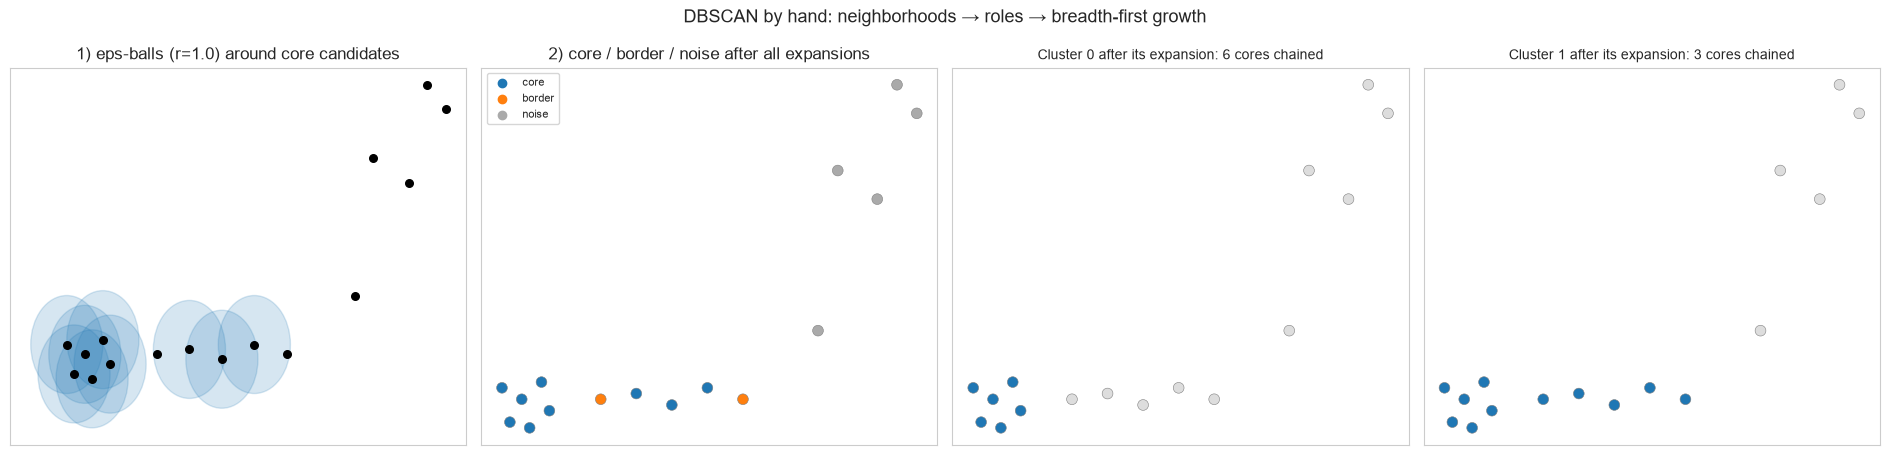

💡 Read the four panels left to right:
   • shaded circles = eps-neighborhoods of the points that have enough friends (cores)
   • the clump is one island of cores; the chain is cores connected END-TO-END by thin links
   • the chain's two SPARSE END POINTS are not cores — but a core reaches them → border members
   • the five scattered points are reached by nobody → noise (-1)
   • the cluster SHAPES fall out of the growth, not out of any centroid geometry


In [2]:
# Walk DBSCAN's decision machinery by hand on a tiny hand-placed dataset:
# 6 clump points (dense), 5 chain points (a chain of 3 cores + 2 sparse ends), 5 far noise points
X_tiny = np.array([
    [ 0.0,  0.0], [ 0.5,  0.3], [-0.5,  0.2], [ 0.2, -0.5], [-0.3, -0.4], [ 0.7, -0.2],   # clump
    [ 2.0,  0.0], [ 2.9,  0.1], [ 3.8, -0.1], [ 4.7,  0.2], [ 5.6,  0.0],                 # chain
    [ 7.5,  1.2], [ 8.0,  4.0], [ 9.0,  3.5], [10.0,  5.0], [ 9.5,  5.5],                 # scattered
])
EPS, MIN_SAMPLES = 1.0, 3

# --- the two decisions every implementation starts with ---
dists = np.sqrt(((X_tiny[:, None, :] - X_tiny[None, :, :]) ** 2).sum(axis=2))   # (16, 16)
neighborhoods = dists <= EPS                     # row i's eps-ball (includes i itself!)
core_mask = neighborhoods.sum(axis=1) >= MIN_SAMPLES

roles = np.where(core_mask, "core", "unassigned")
print("Point-by-point classification (eps=1.0, min_samples=3):")
print(f"{'row':>3s} {'point':>12s} {'|N_eps|':>7s} {'role':>10s}")
for i, (x, n_nbr, role) in enumerate(zip(X_tiny, neighborhoods.sum(axis=1), roles)):
    print(f"{i:3d} ({x[0]:5.1f},{x[1]:4.1f}) {n_nbr:7d} {role:>10s}")

# --- the BFS expansion, recorded frame by frame (same loop as DBSCANScratch) ---
labels = np.full(len(X_tiny), -1)
frames, cluster_id = [], 0
for i in range(len(X_tiny)):
    if not core_mask[i] or labels[i] != -1:
        continue
    labels[i] = cluster_id
    frontier, ptr = [i], 0
    while ptr < len(frontier):
        core = frontier[ptr]; ptr += 1
        for j in np.flatnonzero(neighborhoods[core]):
            if labels[j] != -1:
                continue
            labels[j] = cluster_id
            if core_mask[j]:
                frontier.append(int(j))
    frames.append((f"Cluster {cluster_id} after its expansion: {len(frontier)} cores chained",
                   labels.copy()))
    cluster_id += 1

final_counts = {f"cluster {c}": int((labels == c).sum()) for c in np.unique(labels) if c >= 0}
final_counts["noise"] = int((labels == -1).sum())
print(f"\nExpansion result: {final_counts}")

# --- visualize: eps-balls → roles → growth frames ---
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))

axes[0].set_title(f"1) eps-balls (r={EPS}) around core candidates")
for i in np.flatnonzero(core_mask):
    axes[0].add_patch(Circle(X_tiny[i], EPS, color="#1f77b4", alpha=0.18, zorder=0))
axes[0].scatter(*X_tiny.T, s=30, c="k", zorder=3)

role_colors = np.array(["#1f77b4", "#ff7f0e", "#aaaaaa"])  # core, border, noise
role_of = np.where(core_mask, 0, np.where(labels >= 0, 1, 2))
axes[1].set_title("2) core / border / noise after all expansions")
axes[1].scatter(*X_tiny.T, c=role_colors[role_of], s=60, edgecolors="gray", linewidths=0.4)
for handle, name in zip(role_colors, ["core", "border", "noise"]):
    axes[1].scatter([], [], c=handle, label=name)
axes[1].legend(fontsize=8, loc="upper left")

for ax, (title, snapshot) in zip(axes[2:], frames):
    ax.set_title(title, fontsize=10)
    ax.scatter(*X_tiny.T, c=np.where(snapshot >= 0, "#1f77b4", "#dddddd"), s=60,
               edgecolors="gray", linewidths=0.4)
    ax.set_xticks([]); ax.set_yticks([])

for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("DBSCAN by hand: neighborhoods → roles → breadth-first growth", fontsize=13)
plt.tight_layout()
plt.show()

print("💡 Read the four panels left to right:")
print("   • shaded circles = eps-neighborhoods of the points that have enough friends (cores)")
print("   • the clump is one island of cores; the chain is cores connected END-TO-END by thin links")
print("   • the chain's two SPARSE END POINTS are not cores — but a core reaches them → border members")
print("   • the five scattered points are reached by nobody → noise (-1)")
print("   • the cluster SHAPES fall out of the growth, not out of any centroid geometry")

---

## 3. Assumptions & Requirements

### The Assumptions DBSCAN Makes (and quietly breaks when violated!)

DBSCAN's assumptions are about **density**, and they are stricter than they look:

1. **One global density yardstick (`eps`) fits all clusters**
   - `eps` is *one* number for the whole dataset — clusters are found wherever the local
     density clears that single bar
   - A dense cluster and a diffuse cluster in the same dataset: the `eps` that works for one
     starves or welds the other — DBSCAN's **documented worst enemy** (demoed in §11)
   - HDBSCAN exists precisely because of this bullet (§8, §11)

2. **`eps` is meaningful in the units you feed it**
   - Distances live in raw feature units — `eps=0.5` on scaled z-units and `eps=0.5` on
     raw dollar-features are *different universes* (demo in §4: the default `eps=0.5`
     on income-in-thousands calls every row noise!)
   - "Scaling" here is not a formality (as in K-Means) — it is *choosing the space in which
     your eps means what you think it means*

3. **Clusters are denser than their surroundings** (by at least the `eps`/`min_samples` contrast)
   - Two groups blended into one continuous density gradient will merge — density knows no boundary where there is no dip

4. **Border points are genuinely ambiguous — and claimed first-come-first-served**
   - A border point within `eps` of two clusters joins whoever reaches it first (row order!)
   - Fine at low noise; at heavy noise + adjacent clusters, border membership can shift between runs/datasets — ids are cosmetic, the partition is the product

5. **The neighborhood structure survives dimensionality**
   - In high dimensions nearest-neighbor distances concentrate (everyone is roughly equidistant)
     → the k-distance curve loses its knee → `eps` becomes guesswork (nb 15's PCA is the standard pre-treatment)

6. **Numeric features + a meaningful metric**
   - Euclidean by default; `metric=` swaps the ruler (sklearn-side; the twin is euclidean brute-force)
   - NaNs break distance computation — impute first (same as every distance-based method)

### What DBSCAN Does NOT Require

✅ **No target variable** — unsupervised, like 12/13
✅ **No k declared** — discovered from the density structure (the headline difference)
✅ **No convex/blob geometry** — clusters may be rings, moons, spirals, S-shapes
✅ **No centroid model** — nothing assumes "the cluster has a center of mass"
✅ **No randomness to control** — fully deterministic (no seeds, no restarts)

### What DBSCAN DOES Require in Practice

| Requirement | Why | Fix if violated |
|---|---|---|
| **A sensible `eps` in the data's units** | THE parameter; knee plot recipe (§7) | read the k-distance knee; never guess blind |
| **`min_samples` ≥ ~2 × dims (rule of thumb)** | Sander et al. (1998); makes core semantics stable | 5 is the classic default for 2-D; raise with dimensionality |
| **Roughly uniform density across clusters** | one global `eps` | HDBSCAN / OPTICS (§8, §11) |
| **Modest n** | O(n²) brute memory (the twin); sklearn's bulk caveat | spatial index (sklearn default), subsample, dedupe + `sample_weight` |
| **Low-ish dimensionality** | distance concentration kills the knee | PCA first (nb 15), or feature-select |
| **No missing values** | distance undefined at NaN | impute / drop |

### Transductive by Design: the "No predict" Contract

Like hierarchical clustering (nb 13) and unlike K-Means, **fitted DBSCAN cannot label new
rows** — there is no `predict` on sklearn's DBSCAN or on the twin. The cluster *is* the set
of points; there is no model object to apply elsewhere. The standard workarounds (recipe in §9):
- assign a new row the label of its **nearest core point** (nearest-neighbor against `components_`)
- or refit including the new rows (cheap at small n)

### Key Differences from the Supervised Notebooks (01–11) — and from 12/13

| Aspect | DBSCAN | K-Means (nb 12) | Hierarchical (nb 13) |
|---|---|---|---|
| **k declared?** | ❌ discovered | ✅ required | cut decides (but you pass `n_clusters`) |
| **Noise handling** | **labels -1** | must join a cluster | must join a cluster |
| **Cluster shapes** | any (density-chained) | convex Voronoi cells | linkage-dependent |
| **New rows** | ❌ transductive | ✅ `.predict()` | ❌ transductive |
| **Randomness** | none (row-order only) | seeds + restarts | none |
| **Primary knob** | `eps` (in data units!) | k | linkage rule |

---

## 4. When to Use This Algorithm

### ✅ Use DBSCAN When:

1. **Noise/outliers are real and must be flagged, not absorbed**
   - Fraud screening, sensor glitches, spam accounts: the -1 list is the deliverable (§10 Example 2)
   - K-Means would force every outlier into some cluster; DBSCAN refuses

2. **Cluster shapes are unknown or non-convex**
   - Rings, moons, spirals, river networks, L-shaped regions (§5 payoff cell)
   - Any structure reachable by chaining dense neighborhoods

3. **k is unknown, and imposing one would be a lie**
   - Exploratory analysis of unlabeled data; the count falls out of the density
   - No elbow ambiguity, no silhouette-ladder debate about k

4. **Geospatial / spatial data (the algorithm's native habitat)**
   - Hotspot detection on coordinates: city centers, accident clusters, service areas (§10 Example 1)
   - Units are meaningful (km, m) → `eps` has a physical interpretation

5. **You need a robust baseline that cannot be destabilized by seeding**
   - No `n_init` roulette, no local-minimum lottery — deterministic output (fine print: border order, §3)

6. **Segment sizes are wildly unequal**
   - Density contrast between groups is *fine* (as long as each clears the eps bar) — K-Means fragments big clusters instead

### ❌ Avoid DBSCAN When:

1. **Densities vary strongly across the clusters you care about**
   - The single global `eps` starves diffuse clusters or welds dense ones (§11 demo)
   - Use **HDBSCAN** — its entire reason to exist (§8, §11)

2. **You must label NEW rows after fitting**
   - No `.predict` — transductive only (§3); use K-Means, or the nearest-core workaround (§9)

3. **Data is high-dimensional without preprocessing**
   - Distance concentration → the knee plot goes flat → eps is a coin flip
   - PCA first (nb 15), or choose a method less tied to neighborhoods

4. **n is large and memory is tight**
   - O(n²) pairwise memory for the brute-force twin (~3.2 GB at n=20k); sklearn's bulk
     implementation has a documented worst-case too — `radius_neighbors_graph` / OPTICS escape hatches (§8)

5. **You need soft memberships or probability estimates**
   - Hard labels only (GMM for probabilities; HDBSCAN's `probabilities_` as a partial answer)

6. **Every point MUST be assigned a group (no "unassigned" allowed downstream)**
   - Some pipelines can't tolerate a -1 class — either treat noise explicitly or use a method that assigns everyone

7. **The "density" in your features is an artifact of units**
   - Mixed-unit raw features make eps meaningless (§4's demo) — scale first or define your metric

### DBSCAN vs the Siblings at a Glance (full comparison in §11)

**vs K-Means (nb 12):**
- DBSCAN: discovers k, labels noise, any shape; needs meaningful eps; no predict
- K-Means: needs k, convex blobs only, absorbs outliers, but fast + predicts new rows

**vs Hierarchical (nb 13):**
- DBSCAN: noise class; shape-free; one density threshold; O(n²) brute memory
- Hierarchical: full dendrogram, four linkage geometries, deterministic, no noise class

**vs HDBSCAN (sklearn 1.9, bonus):**
- DBSCAN: flat clusters at one eps — the classic, cheap and transparent
- HDBSCAN: varies the density cut per cluster — the fix for bullet 1 of §3's assumptions

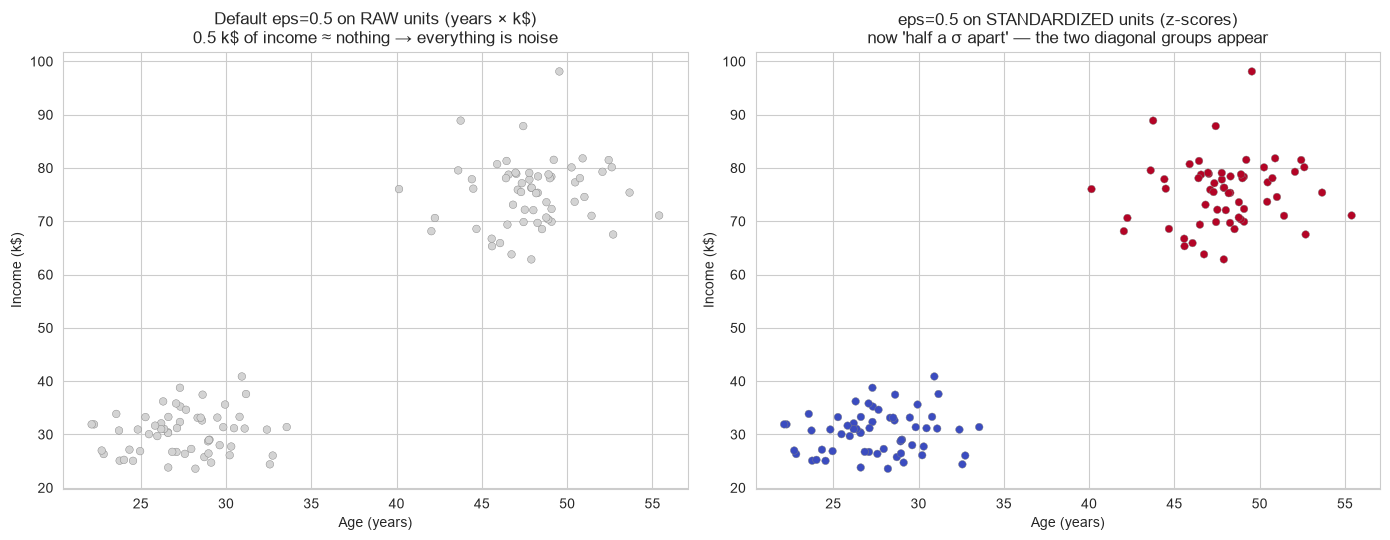

RAW units, eps=0.5:      clusters = 0, noise share = 100%  ← the default eps is nonsense here
STANDARDIZED, eps=0.5:   clusters = 2, noise share = 0%

💡 The left panel is the single most common real-world DBSCAN accident:
   • eps=0.5 was 'chosen' by nobody — it is just the sklearn/twin default
   • in raw dollar-units, NO two customers are within 0.5 k$ of each other → 100% noise
   • the SAME eps on z-scaled features is a meaningful radius and finds the structure
   • K-Means degrades GRACEFULLY under scaling mistakes; DBSCAN degrades CATASTROPHICALLY
     (0 clusters) or accidentally (wrong scale = wrong clusters) — units are the first thing to check


In [3]:
# WHY "eps is in your units" matters: the default eps=0.5 is meaningless on raw features
np.random.seed(42)

# 120 customers: age (years) and income (k$/yr) — two diagonal groups (young+low vs old+high)
n_grp = 60
age = np.concatenate([np.random.normal(28, 3.0, n_grp), np.random.normal(48, 3.0, n_grp)])
income = np.concatenate([np.random.normal(30, 4.0, n_grp), np.random.normal(75, 6.0, n_grp)])
X_units = np.column_stack([age, income])                     # raw units: years × k$
X_units_scaled = StandardScaler().fit_transform(X_units)     # z-units

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# LEFT: DBSCAN's DEFAULT eps=0.5 — but 0.5 of WHAT? On raw features, 0.5 k$ is nothing.
db_raw_default = DBSCANScratch(eps=0.5, min_samples=5).fit(X_units)
axes[0].scatter(age, income, c=np.where(db_raw_default.labels_ == -1, "lightgray", "#1f77b4"),
                s=30, edgecolors="gray", linewidths=0.3)
axes[0].set_title("Default eps=0.5 on RAW units (years × k$)\n0.5 k$ of income ≈ nothing → everything is noise")
axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("Income (k$)")

# RIGHT: same data scaled to z-units — now eps=0.5 means 'half a standard deviation'
db_scaled = DBSCANScratch(eps=0.5, min_samples=5).fit(X_units_scaled)
mask_scaled = db_scaled.labels_ == -1
axes[1].scatter(age[~mask_scaled], income[~mask_scaled], c=db_scaled.labels_[~mask_scaled],
                cmap="coolwarm", s=30, edgecolors="gray", linewidths=0.3)
axes[1].scatter(age[mask_scaled], income[mask_scaled], c="lightgray", s=30,
                edgecolors="gray", linewidths=0.3)
axes[1].set_title("eps=0.5 on STANDARDIZED units (z-scores)\nnow 'half a σ apart' — the two diagonal groups appear")
axes[1].set_xlabel("Age (years)"); axes[1].set_ylabel("Income (k$)")

plt.tight_layout()
plt.show()

noise_raw = (db_raw_default.labels_ == -1).mean()
n_clust_raw = len(set(db_raw_default.labels_)) - (1 if -1 in db_raw_default.labels_ else 0)
n_clust_scaled = len(set(db_scaled.labels_)) - (1 if -1 in db_scaled.labels_ else 0)
print(f"RAW units, eps=0.5:      clusters = {n_clust_raw}, noise share = {noise_raw:.0%}  ← the default eps is nonsense here")
print(f"STANDARDIZED, eps=0.5:   clusters = {n_clust_scaled}, noise share = {(db_scaled.labels_ == -1).mean():.0%}")

print("\n💡 The left panel is the single most common real-world DBSCAN accident:")
print("   • eps=0.5 was 'chosen' by nobody — it is just the sklearn/twin default")
print("   • in raw dollar-units, NO two customers are within 0.5 k$ of each other → 100% noise")
print("   • the SAME eps on z-scaled features is a meaningful radius and finds the structure")
print("   • K-Means degrades GRACEFULLY under scaling mistakes; DBSCAN degrades CATASTROPHICALLY")
print("     (0 clusters) or accidentally (wrong scale = wrong clusters) — units are the first thing to check")

---

## 5. Implementation from Scratch (NumPy)

Let's implement DBSCAN from scratch to understand exactly what the density machinery does —
neighborhoods, core classification, breadth-first growth, border claiming, and the noise verdict.

In [4]:
# Our from-scratch implementation
import sys
sys.path.append('../src')

from models.clustering_models import DBSCANScratch

print("✅ Imported custom DBSCAN implementation!")
print("\nAvailable class: DBSCANScratch")
print("  • DBSCANScratch(eps, min_samples)                — only two parameters; that IS the model")
print("  • .fit(X) → labels every row as member, border, or noise")
print("  • .fit_predict(X) → fit + return the training labels (noise = -1)")
print("  • NO .predict(X_new) — DBSCAN is transductive, like sklearn's (by design!)")
print("\nFitted attributes (same names as sklearn, by design):")
print("  • labels_               (n_samples,)  — 0..k-1 for members, -1 for noise")
print("  • core_sample_indices_  (m,)          — sorted indices of the core points")
print("  • components_           (m, n_features) — copies of the core rows themselves")

✅ Imported custom DBSCAN implementation!

Available class: DBSCANScratch
  • DBSCANScratch(eps, min_samples)                — only two parameters; that IS the model
  • .fit(X) → labels every row as member, border, or noise
  • .fit_predict(X) → fit + return the training labels (noise = -1)
  • NO .predict(X_new) — DBSCAN is transductive, like sklearn's (by design!)

Fitted attributes (same names as sklearn, by design):
  • labels_               (n_samples,)  — 0..k-1 for members, -1 for noise
  • core_sample_indices_  (m,)          — sorted indices of the core points
  • components_           (m, n_features) — copies of the core rows themselves


DBSCAN (FROM SCRATCH)

📊 Dataset:
  Samples: 450
  Features: 2
  True generating clusters (external check only): 4

📈 Fit results:
  Clusters DISCOVERED (we never declared k): 4
  Cluster sizes: [110 112 111 112]
  Core points: 429 of 450 rows
  Border points: 16
  Noise (-1): 5 rows
  components_ shape: (429, 2) (the core rows, copied out)

🔍 Quality:
  Adjusted Rand Index vs 'truth' (synthetic only!): 0.9850
  Silhouette on non-noise rows (internal metric):   0.8184


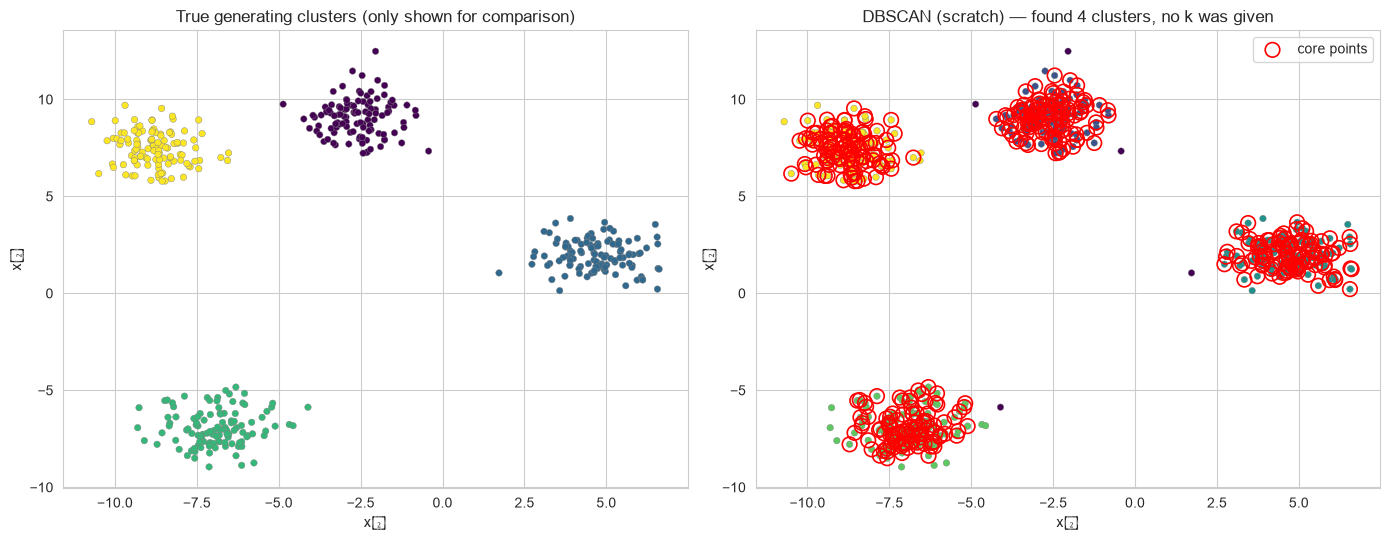

💡 What to notice:
  • k was never passed — the four blobs exist as four connected core-chains and DBSCAN finds them
  • the red rings mark CORE points — the skeleton every cluster grows along
  • on clean separated blobs there is no noise and almost no border drama: the honest case


In [5]:
# The sibling-canonical blobs dataset (same as notebooks 12/13) — well-separated, low noise
X_blobs, y_true_blobs = make_blobs(n_samples=450, centers=4, cluster_std=0.9, random_state=42)

print("=" * 60)
print("DBSCAN (FROM SCRATCH)")
print("=" * 60)
print(f"\n📊 Dataset:")
print(f"  Samples: {len(X_blobs)}")
print(f"  Features: {X_blobs.shape[1]}")
print(f"  True generating clusters (external check only): {len(np.unique(y_true_blobs))}")

# THE two hyperparameters — notice there is no k, no n_init, no random_state anywhere
dbscan_scratch = DBSCANScratch(eps=0.9, min_samples=5)
dbscan_scratch.fit(X_blobs)

labels = dbscan_scratch.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

print(f"\n📈 Fit results:")
print(f"  Clusters DISCOVERED (we never declared k): {n_clusters}")
print(f"  Cluster sizes: {np.bincount(labels[labels >= 0])}")
print(f"  Core points: {len(dbscan_scratch.core_sample_indices_)} of {len(X_blobs)} rows")
print(f"  Border points: {((labels >= 0) & ~np.isin(np.arange(len(X_blobs)), dbscan_scratch.core_sample_indices_)).sum()}")
print(f"  Noise (-1): {(labels == -1).sum()} rows")
print(f"  components_ shape: {dbscan_scratch.components_.shape} (the core rows, copied out)")

# External check (synthetic-land only — in practice there is no y)
ari_ext = adjusted_rand_score(y_true_blobs, labels)
mask_pos = labels >= 0
sil_int = silhouette_score(X_blobs[mask_pos], labels[mask_pos]) if n_clusters >= 2 else float("nan")
print(f"\n🔍 Quality:")
print(f"  Adjusted Rand Index vs 'truth' (synthetic only!): {ari_ext:.4f}")
print(f"  Silhouette on non-noise rows (internal metric):   {sil_int:.4f}")

# Visualize: truth vs discovered — plus the core points highlighted
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_true_blobs, cmap="viridis", s=22, edgecolors="gray", linewidths=0.3)
axes[0].set_title("True generating clusters (only shown for comparison)")
axes[0].set_xlabel("x₀"); axes[0].set_ylabel("x₁")

axes[1].scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels, cmap="viridis", s=22, edgecolors="gray", linewidths=0.3)
axes[1].scatter(X_blobs[dbscan_scratch.core_sample_indices_, 0], X_blobs[dbscan_scratch.core_sample_indices_, 1],
                facecolors="none", edgecolors="red", s=110, linewidths=1.2, label="core points", zorder=5)
axes[1].set_title(f"DBSCAN (scratch) — found {n_clusters} clusters, no k was given")
axes[1].set_xlabel("x₀"); axes[1].set_ylabel("x₁")
axes[1].legend()

plt.tight_layout()
plt.show()

print("💡 What to notice:")
print("  • k was never passed — the four blobs exist as four connected core-chains and DBSCAN finds them")
print("  • the red rings mark CORE points — the skeleton every cluster grows along")
print("  • on clean separated blobs there is no noise and almost no border drama: the honest case")

### How the Scratch Version Works (a guided tour)

Read `src/models/clustering_models.py` alongside these five facts:

**1. The shared distance identity does all the geometry — `_squared_distances`.**
$$\lVert a - b \rVert^2 = \lVert a \rVert^2 + \lVert b \rVert^2 - 2\, a \cdot b$$
The same helper the K-Means and agglomerative twins use: the full $(n \times n)$ matrix is one
matrix product plus two norm broadcasts, with round-off negatives clipped to zero. `fit()`
takes one `sqrt` of it and **never computes a distance again** — every decision below reads
this matrix.

**2. Neighborhoods and cores are two vectorized lines.**
`neighborhoods = distances <= eps` — a boolean $(n \times n)$ matrix whose row $i$ *is*
point $i$'s eps-ball (the diagonal is True: **the point counts itself**, which is exactly
sklearn's documented `min_samples` semantics). Then `core_mask = neighborhoods.sum(axis=1) >= min_samples`.
After these lines, DBSCAN's "hard part" (density) is finished — what remains is bookkeeping.

**3. The expansion is breadth-first with a plain list + read pointer.**
For each unassigned core point `i` (scanned in index order), its cluster grows: a `frontier`
list of cores and a `ptr` that walks it; each frontier core claims its still-unlabeled
neighbors — core neighbors join the frontier (they expand further), non-core neighbors are
claimed as **border** and expand nothing. No recursion (long chains would blow the stack),
no `collections.deque` — a list and an integer pointer are the whole queue.

**4. Border points are claimed first-come-first-served — and that matches sklearn.**
A border point within `eps` of two clusters belongs to whoever reached it first; once
labeled, later clusters skip it. This is not an approximation — it is sklearn's own
index-order expansion, and the repo's behavioral tests pin **exact** agreement: same noise
mask as `sklearn.DBSCAN`, and ARI = 1.0 on the non-noise rows. Label *ids* are cosmetic
(scan-order artifacts); the partition is the product.

**5. The fitted attributes ARE the model — and there is no `predict`.**
`labels_` (members + noise), `core_sample_indices_` (sorted), `components_` (the core rows
themselves). Nothing else is needed downstream: profiles, silhouettes, and the nearest-core
workaround for new rows (§9) all build on these three arrays. There is deliberately **no
`predict`** — DBSCAN defines no rule for unseen rows, exactly like sklearn's estimator.

**What's deliberately simplified vs. sklearn** (also documented at the top of `clustering_models.py`):
- **one brute-force pairwise matrix** — sklearn uses spatial indexes (kd/ball tree, `algorithm='auto'`)
  and degrades gracefully to n in the hundreds of thousands; the twin's O(n²) memory is the honest wall
- **euclidean only** — sklearn accepts any `metric=` (incl. `'precomputed'` matrices)
- **no `sample_weight`** — sklearn lets a heavy row be a core point by itself (§6's demo)

In [6]:
# Reconstruct the twin's results BY HAND on the §2 tiny dataset (16 points) — every decision visible
# Hand version mirrors DBSCANScratch's exact loop so agreement is checkable step by step.

print("=" * 62)
print("HAND-WALK: DBSCAN DECISION BY DECISION (X_tiny, eps=1.0, min_samples=3)")
print("=" * 62)

# Decision 1 — the distance matrix (rounded print: this is all the geometry there is)
dists_hand = np.sqrt(((X_tiny[:, None, :] - X_tiny[None, :, :]) ** 2).sum(axis=2))
np.fill_diagonal(dists_hand, np.inf)          # hide self-distance for the readable view
print("\nPairwise distances (first 8 rows × all 16 cols, ∞ on the diagonal):")
print(pd.DataFrame(dists_hand[:8].round(2)).to_string())

# Decision 2 — neighborhoods and core marks
nbr_hand = dists_hand <= 1.0                  # diagonal is inf → False here; add self separately
nbr_hand |= np.eye(len(X_tiny), dtype=bool)   # self counts (the twin's `distances <= eps` has True on the diagonal)
core_hand = nbr_hand.sum(axis=1) >= 3
print(f"\n|N_eps| per point (self included): {nbr_hand.sum(axis=1)}")
print(f"core mask: {core_hand.astype(int)}")

# Decision 3 — the breadth-first expansion, narrated
labels_hand = np.full(len(X_tiny), -1)
cluster_id, trace = 0, []
for i in range(len(X_tiny)):
    if not core_hand[i] or labels_hand[i] != -1:
        continue
    labels_hand[i] = cluster_id
    frontier, ptr = [i], 0
    trace.append(f"seed  : cluster {cluster_id} starts at core row {i}")
    while ptr < len(frontier):
        core = frontier[ptr]; ptr += 1
        for j in np.flatnonzero(nbr_hand[core]):
            if labels_hand[j] != -1:
                continue
            labels_hand[j] = cluster_id
            if core_hand[j]:
                frontier.append(int(j))
                trace.append(f"  core → row {j:2d} joins cluster {cluster_id} (frontier)")
            else:
                trace.append(f"border: row {j:2d} claimed by cluster {cluster_id} (expands nothing)")
    cluster_id += 1

print("\nExpansion trace:")
for line in trace:
    print(" ", line)
print(f"\nHand labels : {labels_hand}")
print("Rows left at -1 after every seed was exhausted = genuine noise (nobody reached them).")

# Cross-check: the twin must produce the identical labeling
twin_check = DBSCANScratch(eps=1.0, min_samples=3).fit(X_tiny)
print(f"\n🤝 twin labels: {twin_check.labels_}")
print(f"🤝 hand == twin: {np.array_equal(labels_hand, twin_check.labels_)}")

print("\n💡 Three decisions, zero magic:")
print("   • distance matrix → threshold at eps (with SELF inside every ball)")
print("   • count ≥ min_samples → core; cores chain; chains grow breadth-first")
print("   • whatever no chain ever touches is noise — DBSCAN's honest 'belongs to nothing'")

HAND-WALK: DBSCAN DECISION BY DECISION (X_tiny, eps=1.0, min_samples=3)

Pairwise distances (first 8 rows × all 16 cols, ∞ on the diagonal):
     0     1     2     3     4     5     6     7     8     9     10    11    12     13     14     15
0   inf  0.58  0.54  0.54  0.50  0.73  2.00  2.90  3.80  4.70  5.60  7.60  8.94   9.66  11.18  10.98
1  0.58   inf  1.00  0.85  1.06  0.54  1.53  2.41  3.32  4.20  5.11  7.06  8.36   9.08  10.60  10.39
2  0.54  1.00   inf  0.99  0.63  1.26  2.51  3.40  4.31  5.20  6.10  8.06  9.31  10.06  11.55  11.32
3  0.54  0.85  0.99   inf  0.51  0.58  1.87  2.77  3.62  4.55  5.42  7.50  9.00   9.67  11.24  11.07
4  0.50  1.06  0.63  0.51   inf  1.02  2.33  3.24  4.11  5.04  5.91  7.96  9.39  10.08  11.63  11.44
5  0.73  0.54  1.26  0.58  1.02   inf  1.32  2.22  3.10  4.02  4.90  6.94  8.42   9.09  10.66  10.48
6  2.00  1.53  2.51  1.87  2.33  1.32   inf  0.91  1.80  2.71  3.60  5.63  7.21   7.83   9.43   9.30
7  2.90  2.41  3.40  2.77  3.24  2.22  0.91   inf  

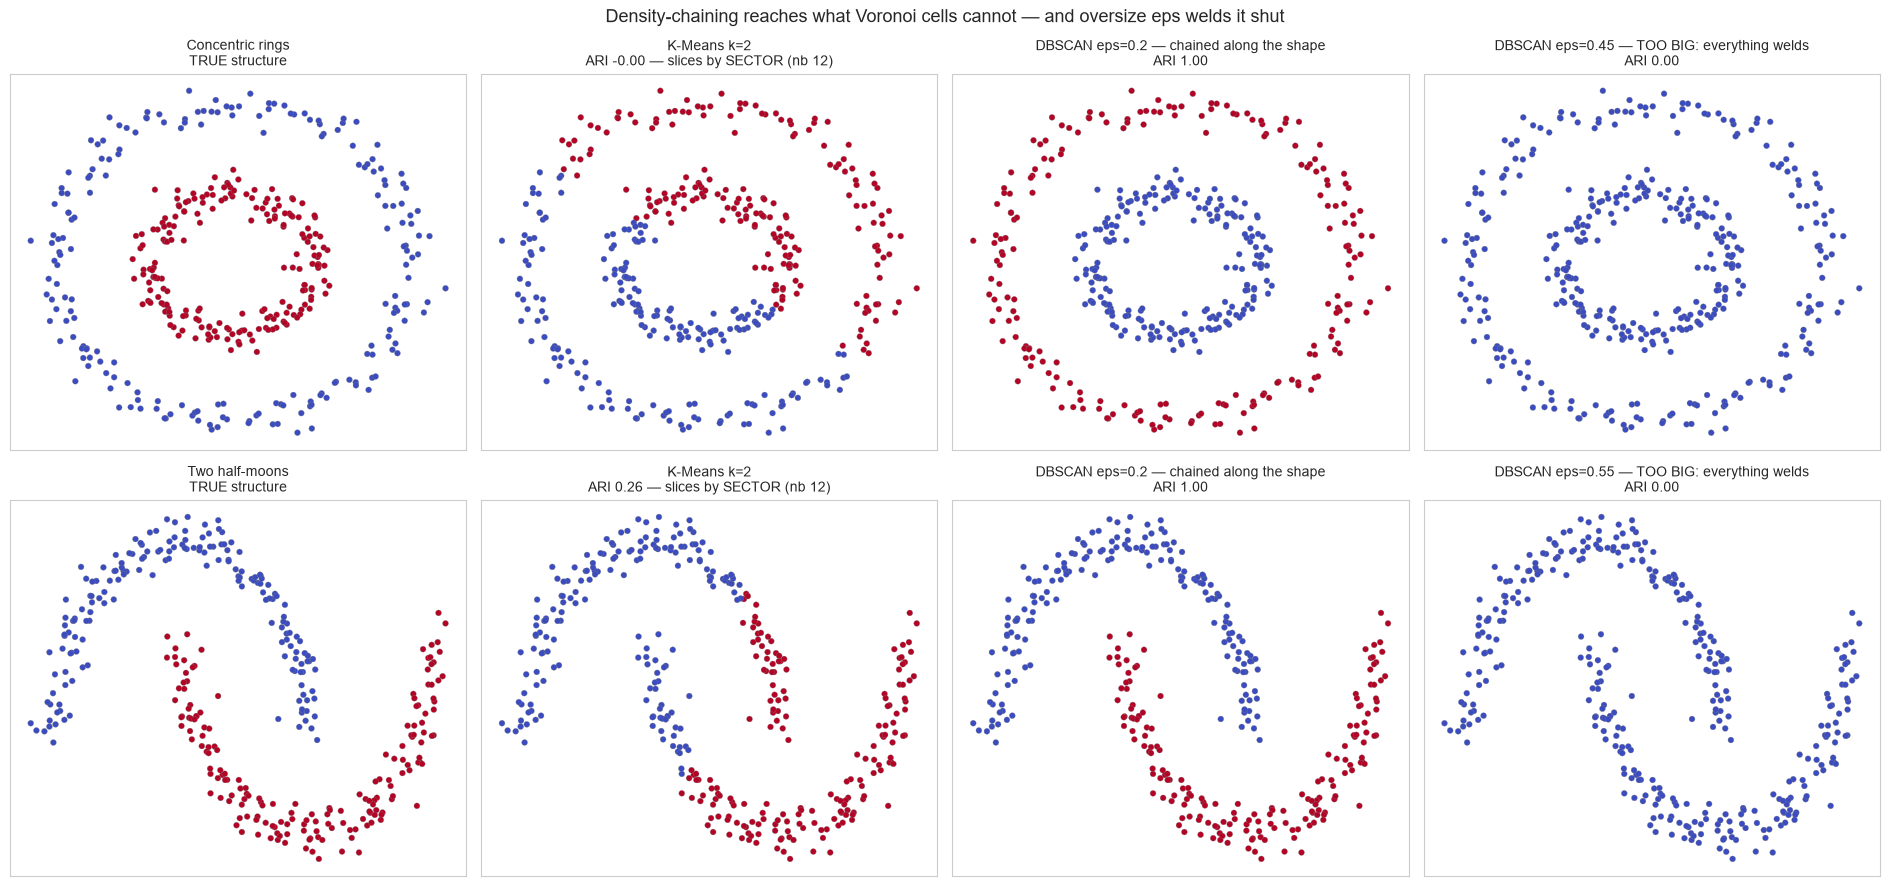

📊 Concentric rings:  K-Means ARI -0.002  |  DBSCAN(0.2) ARI 1.000 (2 clusters, 0 noise)  |  DBSCAN(0.45) ARI 0.000 (1 cluster(s), 0 noise)
📊 Two half-moons:  K-Means ARI 0.257  |  DBSCAN(0.2) ARI 1.000 (2 clusters, 0 noise)  |  DBSCAN(0.45) ARI 0.000 (1 cluster(s), 0 noise)

💡 The middle column is the whole reason DBSCAN exists:
   • a ring's points chain core-to-core AROUND the circle — no centroid geometry required
   • K-Means (col 2) can only cut the plane into Voronoi sectors — nb 12's rings failure, revisited
   • col 4 is the caution: eps past the structure's own gaps and everything welds into one blob
   • tuning eps (§7) = walking between 'starve' and 'weld' — the knee plot finds the window


In [7]:
# THE PAYOFF: structures K-Means provably cannot express — solved by chaining (notebook 12's failure, fixed)
X_rings, y_rings = make_circles(n_samples=400, factor=0.45, noise=0.06, random_state=42)
X_moons, y_moons = make_moons(n_samples=350, noise=0.07, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(19, 9))
payoff = {}

# each geometry gets its own (working eps, weld eps): the weld point sits just past the
# structure's own gap — the rings' radial gap (~0.3) welds at 0.45, the moons' central
# gap (~0.5) welds at 0.55
shape_eps = {
    "Concentric rings": (0.2, 0.45),
    "Two half-moons": (0.2, 0.55),
}
datasets_shape = [(X_rings, y_rings, "Concentric rings"), (X_moons, y_moons, "Two half-moons")]
for row, (X_sh, y_sh, name) in enumerate(datasets_shape):
    eps_ok, eps_weld = shape_eps[name]
    km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_sh)
    ari_km = adjusted_rand_score(y_sh, km.labels_)

    db_ok = DBSCANScratch(eps=eps_ok, min_samples=5).fit(X_sh)
    ari_ok = adjusted_rand_score(y_sh, db_ok.labels_)

    db_weld = DBSCANScratch(eps=eps_weld, min_samples=5).fit(X_sh)
    ari_weld = adjusted_rand_score(y_sh, db_weld.labels_)

    payoff[name] = dict(km=ari_km, db=ari_ok, weld=ari_weld,
                        n_db=len(set(db_ok.labels_)) - (1 if -1 in db_ok.labels_ else 0),
                        n_weld=len(set(db_weld.labels_)) - (1 if -1 in db_weld.labels_ else 0),
                        noise_db=int((db_ok.labels_ == -1).sum()),
                        noise_weld=int((db_weld.labels_ == -1).sum()))

    panels = [
        (y_sh, f"{name}\nTRUE structure"),
        (km.labels_, f"K-Means k=2\nARI {ari_km:.2f} — slices by SECTOR (nb 12)"),
        (db_ok.labels_, f"DBSCAN eps={eps_ok} — chained along the shape\nARI {ari_ok:.2f}"),
        (db_weld.labels_, f"DBSCAN eps={eps_weld} — TOO BIG: everything welds\nARI {ari_weld:.2f}"),
    ]
    for col, (labels_p, title) in enumerate(panels):
        ax = axes[row, col]
        mask_noise = labels_p == -1
        ax.scatter(X_sh[mask_noise, 0], X_sh[mask_noise, 1], c="lightgray", s=16, marker="x")
        ax.scatter(X_sh[~mask_noise, 0], X_sh[~mask_noise, 1], c=labels_p[~mask_noise],
                   cmap="coolwarm", s=18, edgecolors="gray", linewidths=0.2)
        ax.set_title(title, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Density-chaining reaches what Voronoi cells cannot — and oversize eps welds it shut", fontsize=13)
plt.tight_layout()
plt.show()

for name, p in payoff.items():
    print(f"📊 {name}:  K-Means ARI {p['km']:.3f}  |  DBSCAN(0.2) ARI {p['db']:.3f} "
          f"({p['n_db']} clusters, {p['noise_db']} noise)  |  DBSCAN(0.45) ARI {p['weld']:.3f} "
          f"({p['n_weld']} cluster(s), {p['noise_weld']} noise)")

print("\n💡 The middle column is the whole reason DBSCAN exists:")
print("   • a ring's points chain core-to-core AROUND the circle — no centroid geometry required")
print("   • K-Means (col 2) can only cut the plane into Voronoi sectors — nb 12's rings failure, revisited")
print("   • col 4 is the caution: eps past the structure's own gaps and everything welds into one blob")
print("   • tuning eps (§7) = walking between 'starve' and 'weld' — the knee plot finds the window")

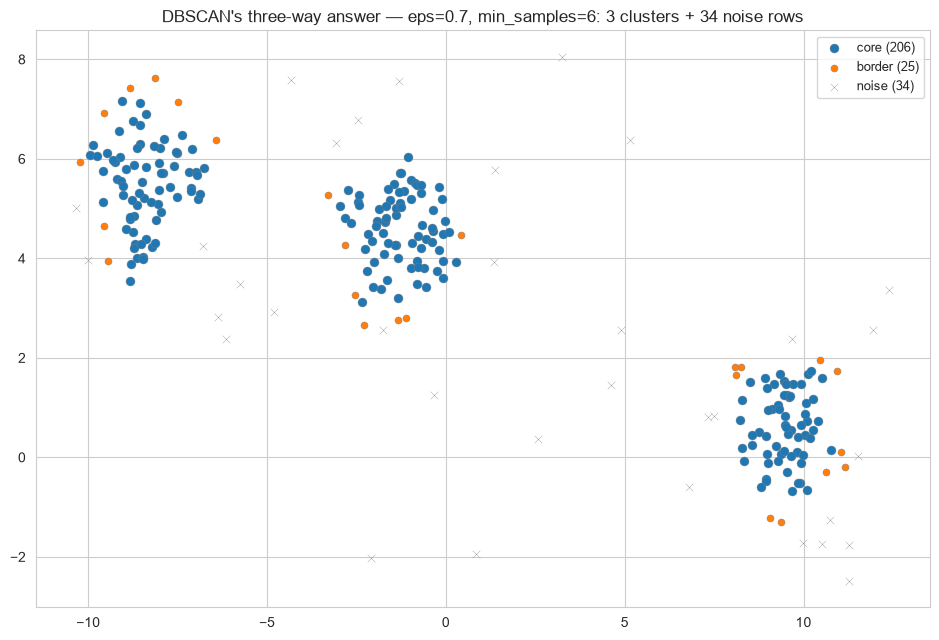

📊 Roles: {np.str_('border'): 25, np.str_('core'): 206, np.str_('noise'): 34}

💡 Reading the three roles:
   • CORE (206 rows) — the interiors; the cluster skeletons
   • BORDER (25 rows) — non-core rows a core reaches: adopted, but they expand nothing
   • NOISE (34 rows) — reached by nobody; 20 of the 25 planted strays are here
   • a stray outlier that lands near a blob is NOT punished — it becomes border (first cluster to reach it claims it)
   • K-Means has no vocabulary for any of this: it must assign every gray × to some centroid


In [8]:
# Core vs border vs noise — the three-way readout DBSCAN gives and K-Means cannot
# Blobs + deliberately scattered no-man's-land rows (the tests' own noisy fixture recipe)
X_blob_part, y_blob_part = make_blobs(n_samples=240, centers=3, cluster_std=0.9, random_state=7)
rng_out = np.random.RandomState(7)
outliers = rng_out.uniform(X_blob_part.min(axis=0) - 1.0, X_blob_part.max(axis=0) + 1.0, size=(25, 2))
X_noisy = np.vstack([X_blob_part, outliers])
y_noisy = np.concatenate([y_blob_part, -np.ones(25, dtype=int)])          # outliers have no true group
is_planted_outlier = np.zeros(len(X_noisy), dtype=bool)
is_planted_outlier[240:] = True

db3 = DBSCANScratch(eps=0.7, min_samples=6).fit(X_noisy)

core_idx = set(db3.core_sample_indices_.tolist())
role = np.array(["border" if (lab >= 0 and i not in core_idx) else
                 "core" if lab >= 0 else "noise"
                 for i, lab in enumerate(db3.labels_)])
n_clusters3 = len(set(db3.labels_)) - (1 if -1 in db3.labels_ else 0)

fig, ax = plt.subplots(figsize=(9.5, 6.5))
style = {"core": ("#1f77b4", "o", 42), "border": ("#ff7f0e", "o", 26), "noise": ("#999999", "x", 30)}
for role_name, (color, marker, size) in style.items():
    m = role == role_name
    ax.scatter(X_noisy[m, 0], X_noisy[m, 1], c=color, marker=marker, s=size,
               label=f"{role_name} ({m.sum()})", edgecolors="gray", linewidths=0.3)
ax.set_title(f"DBSCAN's three-way answer — eps=0.7, min_samples=6: {n_clusters3} clusters "
             f"+ {int((role == 'noise').sum())} noise rows")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"📊 Roles: {dict((k, int(v)) for k, v in zip(*np.unique(role, return_counts=True)))}")
planted_noise = int(((role == 'noise') & is_planted_outlier).sum())
print(f"\n💡 Reading the three roles:")
print(f"   • CORE ({int((role == 'core').sum())} rows) — the interiors; the cluster skeletons")
print(f"   • BORDER ({int((role == 'border').sum())} rows) — non-core rows a core reaches: adopted, but they expand nothing")
print(f"   • NOISE ({int((role == 'noise').sum())} rows) — reached by nobody; {planted_noise} of the {int(is_planted_outlier.sum())} planted strays are here")
print("   • a stray outlier that lands near a blob is NOT punished — it becomes border (first cluster to reach it claims it)")
print("   • K-Means has no vocabulary for any of this: it must assign every gray × to some centroid")

---

## 6. Implementation with Scikit-learn

Now the industry implementation on the same datasets — plus the knobs and machinery the twin
deliberately leaves out.

Facts verified against the shipped documentation of **scikit-learn 1.9** (this repo's pinned version):

- Signature: `DBSCAN(eps=0.5, *, min_samples=5, metric='euclidean', metric_params=None, algorithm='auto', leaf_size=30, p=None, n_jobs=None)`
- There is **no `random_state` parameter** — the fit is deterministic (same fine print as the twin: row order decides border claims)
- `fit(X, y=None, sample_weight=None)` — `y` is ignored; **`sample_weight`** lets one heavy row count as several (a row with weight ≥ `min_samples` is core by itself)
- **No `.predict()`** — `fit_predict(X)` just fits and returns `labels_`; there is no generalization to unseen rows
- Fitted attributes: `labels_` (noise = -1), `core_sample_indices_`, `components_`, plus `n_features_in_` / `feature_names_in_` bookkeeping — the twin exposes the first three, same names, same semantics
- `metric=` accepts any pairwise metric (`'cityblock'`, `'cosine'`, callables, or `'precomputed'` distance matrices); `algorithm` / `leaf_size` / `p` / `n_jobs` are engine knobs — they change speed, never the partition
- Documented memory caveat: this implementation bulk-computes neighborhoods — worst-case O(n²) memory at large `eps` + small `min_samples`; the documented escape hatches are precomputed sparse neighborhoods (`radius_neighbors_graph`) and `OPTICS`
- **See also** in 1.9: `OPTICS` (reachability-based, one fit → many eps cuts) and `HDBSCAN` (varying-density fix, §8/§11)

In [9]:
# sklearn on the SAME blobs data — attribute tour
print("=" * 60)
print("SCIKIT-LEARN DBSCAN (eps=0.9, min_samples=5)")
print("=" * 60)

dbscan_sk = DBSCAN(eps=0.9, min_samples=5).fit(X_blobs)
labels_sk = dbscan_sk.labels_
n_clusters_sk = len(set(labels_sk)) - (1 if -1 in labels_sk else 0)

print(f"\n📊 Fit results:")
print(f"  clusters found (k discovered, never declared): {n_clusters_sk}")
print(f"  cluster sizes     : {np.bincount(labels_sk[labels_sk >= 0])}")
print(f"  core points       : {len(dbscan_sk.core_sample_indices_)}")
print(f"  components_ shape : {dbscan_sk.components_.shape}")
print(f"  n_features_in_    : {dbscan_sk.n_features_in_}")

print(f"\n🔍 External check on this synthetic dataset:")
print(f"  ARI vs generating blobs: {adjusted_rand_score(y_true_blobs, labels_sk):.4f}")

print("\n⚙️ sklearn-only surface the twin doesn't have:")
print("  • metric= (any pairwise metric / 'precomputed'), metric_params, p")
print("  • algorithm= ('auto' | 'ball_tree' | 'kd_tree' | 'brute') + leaf_size — engine knobs, not math knobs")
print("  • n_jobs for parallel neighbor queries")
print("  • fit(..., sample_weight=...) — weighted density (next cells demo it)")

print("\n💡 Same attributes, same names, same semantics as the twin — the app's dual-engine")
print("   contract in miniature. What differs: HOW the neighborhoods are found (tree vs brute),")
print("   not WHAT they mean.")

SCIKIT-LEARN DBSCAN (eps=0.9, min_samples=5)

📊 Fit results:
  clusters found (k discovered, never declared): 4
  cluster sizes     : [110 112 111 112]
  core points       : 429
  components_ shape : (429, 2)
  n_features_in_    : 2

🔍 External check on this synthetic dataset:
  ARI vs generating blobs: 0.9850

⚙️ sklearn-only surface the twin doesn't have:
  • metric= (any pairwise metric / 'precomputed'), metric_params, p
  • algorithm= ('auto' | 'ball_tree' | 'kd_tree' | 'brute') + leaf_size — engine knobs, not math knobs
  • n_jobs for parallel neighbor queries
  • fit(..., sample_weight=...) — weighted density (next cells demo it)

💡 Same attributes, same names, same semantics as the twin — the app's dual-engine
   contract in miniature. What differs: HOW the neighborhoods are found (tree vs brute),
   not WHAT they mean.


In [10]:
# DUAL ENGINE: DBSCANScratch vs sklearn.DBSCAN on the same data — the agreement the tests pin
print("=" * 68)
print("DUAL ENGINE: DBSCANSCRATCH vs SKLEARN.DBSCAN (X_blobs)")
print("=" * 68)
print(f"\n| config               | ARI (twin vs sklearn) | noise-mask equal | twin fit (s) | sklearn fit (s) |")
print(f"|----------------------|-----------------------|------------------|--------------|-----------------|")

configs = [(0.9, 5), (0.7, 6), (1.2, 10)]
for eps_c, ms_c in configs:
    t0 = time.time()
    twin_d = DBSCANScratch(eps=eps_c, min_samples=ms_c).fit(X_blobs)
    t_twin = time.time() - t0
    t0 = time.time()
    sk_d = DBSCAN(eps=eps_c, min_samples=ms_c).fit(X_blobs)
    t_sk = time.time() - t0
    ari_d = adjusted_rand_score(twin_d.labels_, sk_d.labels_)
    same_noise = np.array_equal(twin_d.labels_ == -1, sk_d.labels_ == -1)
    print(f"| eps={eps_c:.1f}, min_samples={ms_c:2d} | {ari_d:21.4f} | {str(same_noise):>16s} | {t_twin:12.4f} | {t_sk:15.4f} |")

print("\n💡 Read the ARI column as the whole story: the twin's brute-force matrix and BFS loop")
print("   reproduce sklearn's partition EXACTLY here (ARI = 1.0) — the repo's behavioral tests")
print("   pin this same contract: identical noise masks, identical non-noise partitions.")
print("   The time columns show why the twin is for READING and sklearn is for RUNNING:")
print("   sklearn's neighbor indexes + C/OpenMP vs a Python loop over an (n × n) matrix.")

# sklearn-only extra #1: algorithm= changes the INDEX, never the ANSWER
print("\n" + "=" * 68)
print("SKLEARN-ONLY EXTRA: algorithm= — same neighborhoods, different lookup machinery")
print("=" * 68)
base_labels = DBSCAN(eps=0.9, min_samples=5, algorithm='brute').fit(X_blobs).labels_
for algo_name in ["auto", "kd_tree", "ball_tree"]:
    labels_algo = DBSCAN(eps=0.9, min_samples=5, algorithm=algo_name).fit(X_blobs).labels_
    print(f"  algorithm={algo_name:9s} → labels identical to brute: {np.array_equal(labels_algo, base_labels)}")
print("  💡 'algorithm' selects HOW neighbor queries run (tree vs scan) — speed knob only;")
print("     the partition is a function of (X, eps, min_samples, metric), nothing else.")

DUAL ENGINE: DBSCANSCRATCH vs SKLEARN.DBSCAN (X_blobs)

| config               | ARI (twin vs sklearn) | noise-mask equal | twin fit (s) | sklearn fit (s) |
|----------------------|-----------------------|------------------|--------------|-----------------|
| eps=0.9, min_samples= 5 |                1.0000 |             True |       0.0113 |          0.0034 |
| eps=0.7, min_samples= 6 |                1.0000 |             True |       0.0072 |          0.0026 |
| eps=1.2, min_samples=10 |                1.0000 |             True |       0.0080 |          0.0022 |

💡 Read the ARI column as the whole story: the twin's brute-force matrix and BFS loop
   reproduce sklearn's partition EXACTLY here (ARI = 1.0) — the repo's behavioral tests
   pin this same contract: identical noise masks, identical non-noise partitions.
   The time columns show why the twin is for READING and sklearn is for RUNNING:
   sklearn's neighbor indexes + C/OpenMP vs a Python loop over an (n × n) matrix.

SKLEARN-ON

In [11]:
# sklearn-only extras: sample_weight and metric='precomputed'
print("=" * 66)
print("SKLEARN-ONLY EXTRAS (twin simplifications, made concrete)")
print("=" * 66)

# --- 1. sample_weight: a heavy row is a core point BY ITSELF ---
X_w = np.array([
    [0.0, 0.0], [0.8, 0.1], [1.7, 0.0],        # a 3-point chain (the MIDDLE point is the only core at eps=1.0, min_samples=3)
    [8.0, 8.0],                                 # far, alone — normally noise
])
db_plain = DBSCAN(eps=1.0, min_samples=3).fit(X_w)
weights = np.array([1, 1, 1, 5])                # the far row 'weighs' 5 ≥ min_samples
db_weighted = DBSCAN(eps=1.0, min_samples=3).fit(X_w, sample_weight=weights)
print(f"\n1️⃣ sample_weight — 'count this row 5 times':")
print(f"   plain    : labels {db_plain.labels_}   (the lone row is noise: nobody reaches it)")
print(f"   weighted : labels {db_weighted.labels_}   (weight ≥ min_samples → core by itself → its own cluster)")
print("   Use for: duplicated observations (count = multiplicity), importance-weighted density")

# --- 2. metric='precomputed': DBSCAN consumes a distance MATRIX instead of coordinates ---
sub = X_blobs[:120]
D_euclid = np.sqrt(((sub[:, None, :] - sub[None, :, :]) ** 2).sum(axis=2))
D_city = np.abs(sub[:, None, :] - sub[None, :, :]).sum(axis=2)     # manhattan, same rows
db_euclid = DBSCAN(eps=0.9, min_samples=5, metric='precomputed').fit(D_euclid)
db_city = DBSCAN(eps=1.3, min_samples=5, metric='precomputed').fit(D_city)
cl_e = len(set(db_euclid.labels_)) - (1 if -1 in db_euclid.labels_ else 0)
cl_c = len(set(db_city.labels_)) - (1 if -1 in db_city.labels_ else 0)
print(f"\n2️⃣ metric='precomputed' — feed ANY dissimilarity matrix:")
print(f"   euclidean matrix (eps=0.9): {cl_e} clusters, {(db_euclid.labels_ == -1).sum()} noise")
print(f"   manhattan matrix (eps=1.3): {cl_c} clusters, {(db_city.labels_ == -1).sum()} noise")
print("   💡 changing the ruler changes the neighborhoods — the partition answers to the metric;")
print("      'precomputed' is also the door for domain distances (route times, alignment scores)")
print("      and the documented big-n escape hatch (sparse radius_neighbors_graph in, chunked).")

print("\n💡 The twin skips both on purpose (brute-force euclidean only) — its docstring says so;")
print("   these two cells are what the sklearn side adds when you need them.")

SKLEARN-ONLY EXTRAS (twin simplifications, made concrete)

1️⃣ sample_weight — 'count this row 5 times':
   plain    : labels [ 0  0  0 -1]   (the lone row is noise: nobody reaches it)
   weighted : labels [0 0 0 1]   (weight ≥ min_samples → core by itself → its own cluster)
   Use for: duplicated observations (count = multiplicity), importance-weighted density

2️⃣ metric='precomputed' — feed ANY dissimilarity matrix:
   euclidean matrix (eps=0.9): 5 clusters, 11 noise
   manhattan matrix (eps=1.3): 4 clusters, 9 noise
   💡 changing the ruler changes the neighborhoods — the partition answers to the metric;
      'precomputed' is also the door for domain distances (route times, alignment scores)
      and the documented big-n escape hatch (sparse radius_neighbors_graph in, chunked).

💡 The twin skips both on purpose (brute-force euclidean only) — its docstring says so;
   these two cells are what the sklearn side adds when you need them.


---

## 7. Hyperparameter Tuning (Choosing eps and min_samples)

**There is no accuracy and no GridSearchCV in this section** — and no inertia to elbow either
(DBSCAN has no objective value). Tuning is a **structural read of the data**, driven by three tools:

1. **The k-distance knee plot** — the standard, data-driven recipe for `eps`: sort every point's
   `min_samples`-th nearest-neighbor distance; the curve's bend marks the density scale
2. **The eps sweep** — clusters found, noise share, and silhouette (on non-noise rows!) vs `eps`;
   read the window between *starve* (all noise) and *weld* (one blob)
3. **min_samples as the strictness dial** — raise it and watch borders become noise and diffuse
   structure dissolve; the classic rule of thumb is `min_samples ≈ 2 × n_features`

We reuse the noisy-blobs data from §5 (three blobs + 25 planted strays): the honest test case,
because a good `eps` must do BOTH jobs — keep the blobs whole and refuse the strays.

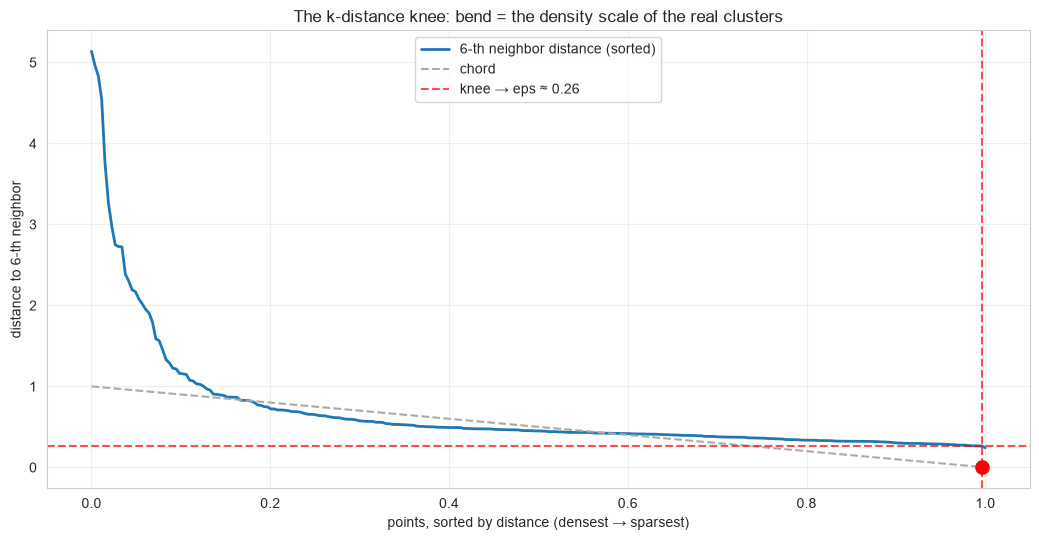

📊 Reading the curve:
  • the plateau on the right: blob rows — their 6-th neighbor is nearby (dense)
  • the tail on the left: the planted strays — even their closest friends are far (sparse)
  • the BEND between them is where 'dense' ends: eps ≈ 0.26

🤝 Fitting AT the knee's eps: 1 clusters, 97% noise
💡 Don't guess eps — read it off the data. The knee marks where 'enough friends within eps'
   stops being true for most points; below it DBSCAN starves, above it clusters weld.


In [12]:
# Tool 1: the k-distance knee plot — the data-driven way to choose eps
MIN_SAMPLES_KNEE = 6

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES_KNEE).fit(X_noisy)
dist_k, _ = nn.kneighbors(X_noisy)
# the k-th returned column IS the |N_eps| that DBSCAN counts (kneighbors includes the point itself)
kth_dist = dist_k[:, -1]

# knee = the curve point farthest from the chord joining its endpoints (kneedle-style, one line of math)
x_norm = np.linspace(0, 1, len(kth_dist))
y_curve = np.sort(kth_dist)[::-1]
y_norm = (y_curve - y_curve.min()) / (y_curve.max() - y_curve.min() + 1e-12)
chord = y_norm[0] + (y_norm[-1] - y_norm[0]) * x_norm
knee_pos = int(np.argmax(y_norm - chord))
eps_knee = float(y_curve[knee_pos])

fig, ax = plt.subplots(figsize=(10.5, 5.5))
ax.plot(x_norm, y_curve, lw=2, color="#1f77b4", label=f"{MIN_SAMPLES_KNEE}-th neighbor distance (sorted)")
ax.plot([x_norm[0], x_norm[-1]], [y_norm[0], y_norm[-1]], "--", color="#aaaaaa", lw=1.5, label="chord")
ax.axvline(x_norm[knee_pos], color="red", ls="--", alpha=0.7)
ax.axhline(eps_knee, color="red", ls="--", alpha=0.7, label=f"knee → eps ≈ {eps_knee:.2f}")
ax.scatter([x_norm[knee_pos]], [y_norm[knee_pos]], c="red", s=90, zorder=5)
ax.set_xlabel("points, sorted by distance (densest → sparsest)")
ax.set_ylabel(f"distance to {MIN_SAMPLES_KNEE}-th neighbor")
ax.set_title("The k-distance knee: bend = the density scale of the real clusters")
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("📊 Reading the curve:")
print(f"  • the plateau on the right: blob rows — their {MIN_SAMPLES_KNEE}-th neighbor is nearby (dense)")
print(f"  • the tail on the left: the planted strays — even their closest friends are far (sparse)")
print(f"  • the BEND between them is where 'dense' ends: eps ≈ {eps_knee:.2f}")

db_knee = DBSCANScratch(eps=eps_knee, min_samples=MIN_SAMPLES_KNEE).fit(X_noisy)
n_knee = len(set(db_knee.labels_)) - (1 if -1 in db_knee.labels_ else 0)
print(f"\n🤝 Fitting AT the knee's eps: {n_knee} clusters, {(db_knee.labels_ == -1).mean():.0%} noise")
print("💡 Don't guess eps — read it off the data. The knee marks where 'enough friends within eps'")
print("   stops being true for most points; below it DBSCAN starves, above it clusters weld.")

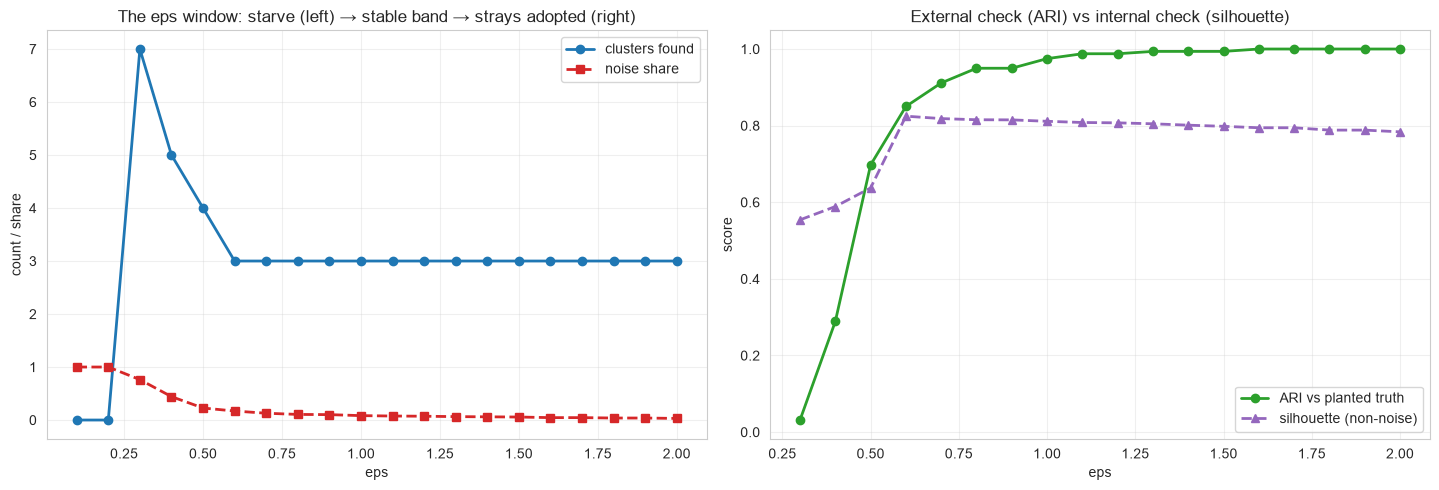

 eps  clusters  noise_pct  silhouette   ari
 0.1         0      1.000         NaN   NaN
 0.2         0      1.000         NaN   NaN
 0.3         7      0.762       0.554 0.032
 0.4         5      0.442       0.589 0.289
 0.5         4      0.226       0.637 0.697
 0.6         3      0.170       0.825 0.850
 0.7         3      0.128       0.818 0.911
 0.8         3      0.106       0.815 0.950
 0.9         3      0.102       0.815 0.950
 1.0         3      0.083       0.811 0.975
 1.1         3      0.075       0.808 0.988
 1.2         3      0.072       0.807 0.988
 1.3         3      0.064       0.805 0.994
 1.4         3      0.060       0.801 0.994
 1.5         3      0.057       0.798 0.994
 1.6         3      0.045       0.794 1.000
 1.7         3      0.045       0.794 1.000
 1.8         3      0.038       0.788 1.000
 1.9         3      0.038       0.788 1.000
 2.0         3      0.030       0.784 1.000

💡 Reading the sweep on this dataset:
  • eps ≤ 0.1: 0 clusters — every poin

In [13]:
# Tool 2: the eps sweep — clusters, noise share, silhouette, and ARI vs the planted truth
eps_values = np.arange(0.1, 2.01, 0.1)
rows_sweep = []
for eps_s in eps_values:
    db_s = DBSCAN(eps=float(eps_s), min_samples=6).fit(X_noisy)
    lab_s = db_s.labels_
    n_c = len(set(lab_s)) - (1 if -1 in lab_s else 0)
    mask_n = lab_s != -1
    sil_s = silhouette_score(X_noisy[mask_n], lab_s[mask_n]) if (n_c >= 2 and mask_n.sum() > n_c) else np.nan
    # ARI vs truth: only the 240 blob rows have a true group — the planted strays don't
    ari_s = adjusted_rand_score(y_noisy[~is_planted_outlier], lab_s[~is_planted_outlier]) if n_c >= 2 else np.nan
    rows_sweep.append(dict(eps=float(eps_s), clusters=n_c, noise_pct=(lab_s == -1).mean(),
                           silhouette=sil_s, ari=ari_s))
df_sweep = pd.DataFrame(rows_sweep)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5))
axes[0].plot(df_sweep.eps, df_sweep.clusters, "o-", color="#1f77b4", lw=2, label="clusters found")
axes[0].plot(df_sweep.eps, df_sweep.noise_pct, "s--", color="#d62728", lw=2, label="noise share")
axes[0].set_xlabel("eps"); axes[0].set_ylabel("count / share")
axes[0].set_title("The eps window: starve (left) → stable band → strays adopted (right)")
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[1].plot(df_sweep.eps, df_sweep.ari, "o-", color="#2ca02c", lw=2, label="ARI vs planted truth")
axes[1].plot(df_sweep.eps, df_sweep.silhouette, "^--", color="#9467bd", lw=2, label="silhouette (non-noise)")
axes[1].set_xlabel("eps"); axes[1].set_ylabel("score")
axes[1].set_title("External check (ARI) vs internal check (silhouette)")
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(df_sweep.round(3).to_string(index=False))

best_row = df_sweep.loc[df_sweep.ari.idxmax()]
print(f"\n💡 Reading the sweep on this dataset:")
print(f"  • eps ≤ 0.1: 0 clusters — every point is stranded (the §4 accident, reproduced); at")
print(f"    eps=0.2 the odd stray junk fragment can flicker into existence before the real work starts")
print(f"  • the working band (≈ {best_row.eps:.1f}): {int(best_row.clusters)} clusters + the strays flagged noise — both jobs done")
print(f"  • eps → 2.0: the blobs never merge (their gaps are far wider), but the strays get adopted")
print(f"    as border members — the noise share drains toward 0: 'noise' is not a fixed property, it is")
print(f"    defined relative to eps")
print(f"  • best ARI row: eps={best_row.eps:.1f} → ARI {best_row.ari:.3f} (truth used for the check ONLY)")

 min_samples  clusters  core_pct  noise_pct  planted_outliers_in_noise
           3         4  0.875472   0.105660                         19
           6         3  0.777358   0.128302                         20
          10         3  0.607547   0.196226                         21
          15         3  0.396226   0.290566                         21
          25         1  0.003774   0.905660                         25
          40         0  0.000000   1.000000                         25


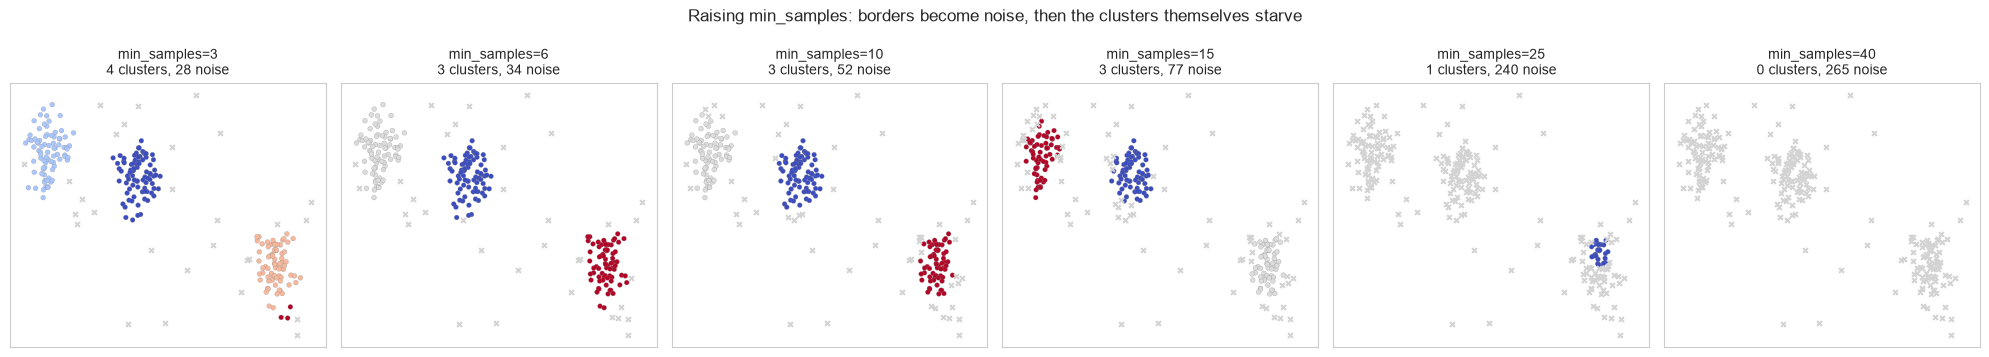


💡 What the dial does (same data, same eps=0.7):
  • min_samples=3: lax — on this fixture the uniform strays clump just enough for one
    junk fragment to qualify as a 'cluster' (watch the table: 4 clusters); the blob
    structure itself is unchanged — the extra label is pure scatter-noise
  • min_samples=6–15: the sweet range for this data — the junk fragment dissolves, blobs
    stay whole, strays flagged
  • min_samples=25–40: brutal — the threshold nears the blobs' own local density, so blob
    EDGES stop qualifying as cores; clusters shrink, fragment, and finally dissolve
    entirely (at 40, zero clusters survive): the threshold is relative to the DENSITY,
    not to your intentions
  • rule of thumb (Sander et al. 1998): min_samples ≈ 2 × n_features; the sklearn default 5
    matches 2-D data exactly — raise it as dimensions grow


In [14]:
# Tool 3: min_samples — the strictness dial (eps fixed at 0.7)
ms_values = [3, 6, 10, 15, 25, 40]
rows_ms = []
for ms_s in ms_values:
    db_m = DBSCANScratch(eps=0.7, min_samples=ms_s).fit(X_noisy)
    lab_m = db_m.labels_
    n_c = len(set(lab_m)) - (1 if -1 in lab_m else 0)
    rows_ms.append(dict(min_samples=ms_s, clusters=n_c,
                        core_pct=(np.isin(np.arange(len(X_noisy)), db_m.core_sample_indices_)).mean(),
                        noise_pct=(lab_m == -1).mean(),
                        planted_outliers_in_noise=int(((lab_m == -1) & is_planted_outlier).sum())))
df_ms = pd.DataFrame(rows_ms)

print(df_ms.to_string(index=False))

fig, axes = plt.subplots(1, 6, figsize=(20, 3.6))
for ax, ms_s in zip(axes, ms_values):
    db_m = DBSCANScratch(eps=0.7, min_samples=ms_s).fit(X_noisy)
    mask_noise = db_m.labels_ == -1
    ax.scatter(X_noisy[~mask_noise, 0], X_noisy[~mask_noise, 1], c=db_m.labels_[~mask_noise],
               cmap="coolwarm", s=12, edgecolors="gray", linewidths=0.15)
    ax.scatter(X_noisy[mask_noise, 0], X_noisy[mask_noise, 1], c="lightgray", marker="x", s=12)
    n_c = len(set(db_m.labels_)) - (1 if -1 in db_m.labels_ else 0)
    ax.set_title(f"min_samples={ms_s}\n{n_c} clusters, {int(mask_noise.sum())} noise", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Raising min_samples: borders become noise, then the clusters themselves starve", fontsize=12)
plt.tight_layout()
plt.show()

print("\n💡 What the dial does (same data, same eps=0.7):")
print("  • min_samples=3: lax — on this fixture the uniform strays clump just enough for one")
print("    junk fragment to qualify as a 'cluster' (watch the table: 4 clusters); the blob")
print("    structure itself is unchanged — the extra label is pure scatter-noise")
print("  • min_samples=6–15: the sweet range for this data — the junk fragment dissolves, blobs")
print("    stay whole, strays flagged")
print("  • min_samples=25–40: brutal — the threshold nears the blobs' own local density, so blob")
print("    EDGES stop qualifying as cores; clusters shrink, fragment, and finally dissolve")
print("    entirely (at 40, zero clusters survive): the threshold is relative to the DENSITY,")
print("    not to your intentions")
print("  • rule of thumb (Sander et al. 1998): min_samples ≈ 2 × n_features; the sklearn default 5")
print("    matches 2-D data exactly — raise it as dimensions grow")

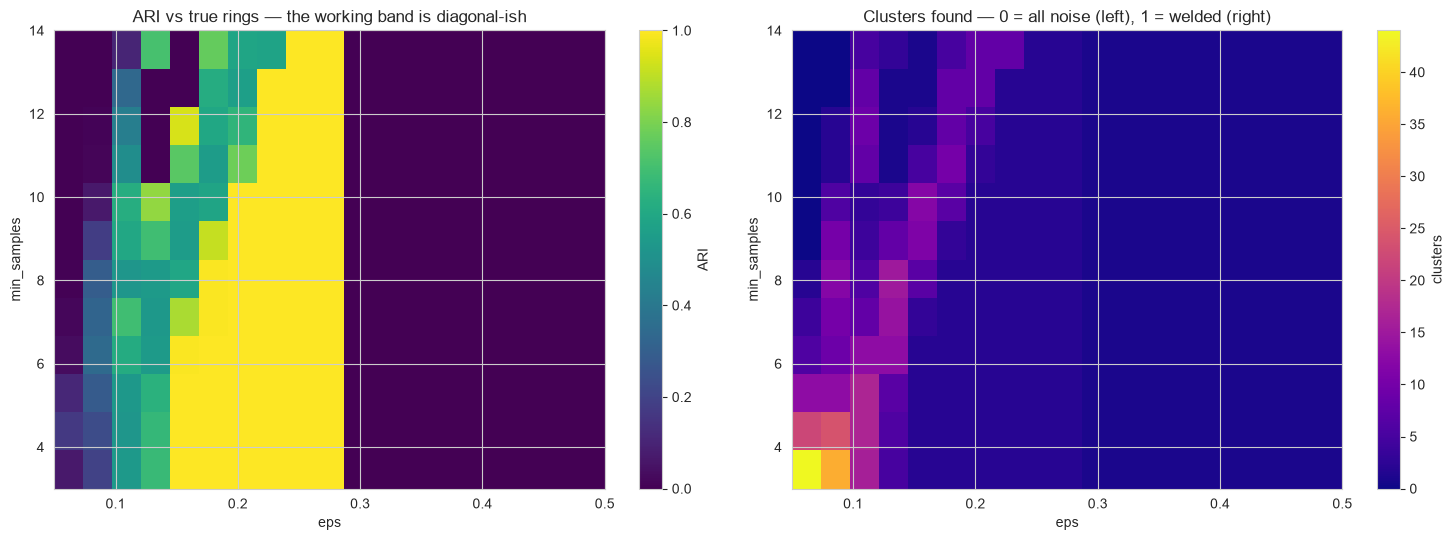

💡 Reading the two maps together (rings data, 400 points, true ring gap ≈ 0.3):
  • LEFT edge of the maps (eps ≤ 0.075): the eps-ball holds too few friends (this ring's
    own spacing beats it) → starve: 0 clusters (the lax corner may flicker a tiny fragment)
    → ARI ≈ 0
  • RIGHT edge (eps ≥ ~0.4): 1 cluster — eps bridges the ~0.3 radial gap → the rings weld → ARI 0
  • the working band sits BETWEEN, and it NARROWS as min_samples grows: a stricter core
    demands wider eps, while the weld wall doesn't move — the band pinches from both sides
  • this is why 'tune eps' is a plot-reading job, not a scalar search: the answer is a region


In [15]:
# The full picture: eps × min_samples jointly, on the rings data — the working band is a REGION, not a point
eps_grid = np.arange(0.05, 0.51, 0.025)
ms_grid = np.arange(3, 15)
ari_grid = np.zeros((len(ms_grid), len(eps_grid)))
counts_grid = np.zeros_like(ari_grid)

for r_i, ms_h in enumerate(ms_grid):
    for c_i, eps_h in enumerate(eps_grid):
        lab_h = DBSCAN(eps=float(eps_h), min_samples=int(ms_h)).fit(X_rings).labels_
        n_h = len(set(lab_h)) - (1 if -1 in lab_h else 0)
        counts_grid[r_i, c_i] = n_h
        ari_grid[r_i, c_i] = adjusted_rand_score(y_rings, lab_h) if n_h >= 2 else 0.0

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
im = axes[0].imshow(ari_grid, origin="lower", aspect="auto", cmap="viridis", vmin=0, vmax=1,
                    extent=[eps_grid[0], eps_grid[-1], ms_grid[0], ms_grid[-1]])
axes[0].set_xlabel("eps"); axes[0].set_ylabel("min_samples")
axes[0].set_title("ARI vs true rings — the working band is diagonal-ish")
plt.colorbar(im, ax=axes[0], label="ARI")

im2 = axes[1].imshow(counts_grid, origin="lower", aspect="auto", cmap="plasma", vmin=0,
                     extent=[eps_grid[0], eps_grid[-1], ms_grid[0], ms_grid[-1]])
axes[1].set_xlabel("eps"); axes[1].set_ylabel("min_samples")
axes[1].set_title("Clusters found — 0 = all noise (left), 1 = welded (right)")
plt.colorbar(im2, ax=axes[1], label="clusters")

plt.tight_layout()
plt.show()

print("💡 Reading the two maps together (rings data, 400 points, true ring gap ≈ 0.3):")
print("  • LEFT edge of the maps (eps ≤ 0.075): the eps-ball holds too few friends (this ring's")
print("    own spacing beats it) → starve: 0 clusters (the lax corner may flicker a tiny fragment)")
print("    → ARI ≈ 0")
print("  • RIGHT edge (eps ≥ ~0.4): 1 cluster — eps bridges the ~0.3 radial gap → the rings weld → ARI 0")
print("  • the working band sits BETWEEN, and it NARROWS as min_samples grows: a stricter core")
print("    demands wider eps, while the weld wall doesn't move — the band pinches from both sides")
print("  • this is why 'tune eps' is a plot-reading job, not a scalar search: the answer is a region")

---

## 8. Complete Hyperparameter Reference

### DBSCAN Parameters (scikit-learn `DBSCAN` 1.9 — twin mirrors the core two)

#### `eps` (float, default=0.5) **[THE GEOMETRY KNOB]**
- **Description**: the maximum distance between two samples for one to be in the other's
  neighborhood — explicitly **not** a maximum bound on how far apart points inside one cluster
  may end up (chains make clusters as wide as the density carries them)
- **Effect on the model**:
  - **Too small** (below the data's own spacing): zero clusters — every row stranded as noise
    (the §4 default-eps accident; the §7 sweep's left edge)
  - **The working band**: clusters emerge and stay separate — found by the knee plot + sweep (§7)
  - **Too large**: everything welds into one blob (the §5 payoff cell's right panel)
- **The unit trap**: eps lives in **whatever units you feed it** — raw mixed units make 0.5
  meaningless; standardized units make 0.5 "half a standard deviation"; on a map, eps in km
  has a *physical* reading (§10 Example 1)
- **Tuning strategy**: k-distance knee (§7 tool 1) → sweep (§7 tool 2) → confirm the noise
  share and cluster count both make domain sense
- **There is no universal good value** — Schubert et al. (2017) is essentially a long paper
  about people misusing this one number
- **Example**: `DBSCAN(eps=0.9, min_samples=5)`

---

#### `min_samples` (int, default=5) **[THE STRICTNESS KNOB]**
- **Description**: how many points (the point **itself included**) an eps-neighborhood must
  hold for the point to be a core point
- **Effect on the model**:
  - **Low (2–3)**: thin fringes qualify as cores → chains through sparse regions, junk
    mini-clusters among strays (single-linkage-flavored behavior)
  - **Default 5**: the classic 2-D value; matches the `2 × dims` rule of thumb (Sander et al. 1998)
  - **High (well above the 2 × dims floor)**: conservative — borders demote to noise, diffuse
    clusters dissolve first, dense survivors stay (§7's dial demo)
- **Interaction with eps**: raising min_samples shifts the working eps band *upward* while the
  weld wall stays put → the usable window narrows (§7's heatmap)
- **Example**: `DBSCAN(min_samples=10)` for 4–5-D data, or to demand sturdier cores

---

#### `metric` (str or callable, default='euclidean') **[sklearn only — twin is euclidean-fixed]**
- **Description**: the distance the neighborhoods are measured in — anything
  `pairwise_distances` accepts: `'cityblock'`, `'cosine'`, `'minkowski'`, callables, or
  **`'precomputed'`** (pass an (n × n) distance matrix to `fit`)
- **Effect**: the ruler defines "close" — swapping it changes neighborhoods, cores, and the
  partition (§6's demo: euclidean vs manhattan on the same rows)
- **Unlike agglomerative's `ward`** (which forces euclidean), DBSCAN accepts any metric freely
- **When to change**: cosine for embedding/TF-IDF geometry; precomputed for domain distances
  (route times, sequence-alignment scores) and as the big-n escape hatch (§6's caveat)
- **Example**: `DBSCAN(metric='precomputed').fit(distance_matrix)`

---

#### `metric_params` (dict, default=None) **[sklearn only]**
- **Description**: extra keyword arguments handed to the metric function (e.g. `p` for minkowski)
- **Example**: `DBSCAN(metric='minkowski', metric_params={'p': 3})`

---

#### `p` (float, default=None) **[sklearn only]**
- **Description**: the Minkowski power when `metric='minkowski'`; `None` means p=2 (euclidean);
  p=1 is Manhattan
- **Example**: `DBSCAN(metric='minkowski', p=1)`

---

#### `algorithm` ({'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto') **[sklearn only — speed only]**
- **Description**: how neighbor queries are computed — spatial index vs brute scan
- **Effect on the model**: **none** — demonstrated in §6: all four choices yield identical
  labels on the same data (the partition is a function of X, eps, min_samples, metric — nothing else)
- **When to change**: high-dim data often does better with `'brute'`; low-dim benefits from trees
- **Example**: `DBSCAN(algorithm='brute')`

---

#### `leaf_size` (int, default=30) **[sklearn only]**
- **Description**: leaf size for BallTree/KDTree — query speed vs tree-build memory
- **Twin**: no index exists to tune (brute force)

---

#### `n_jobs` (int, default=None) **[sklearn only]**
- **Description**: parallel neighbor queries (`-1` = all cores)

---

#### `sample_weight` (parameter of `fit`, default=None) **[sklearn only]**
- **Description**: per-row weight; a row whose weight reaches `min_samples` is a core point
  **by itself**; a negative weight can inhibit neighbors from being core
- **Use for**: duplicated rows (weight = multiplicity — dedupe + weight instead of carrying
  copies), importance-weighted density (§6's demo)
- **Twin**: not implemented (documented simplification)

---

#### Fitted attributes (sklearn = twin, same names)
- `labels_` — cluster id per fitted row; **-1 = noise** (the transductive contract: no `predict`)
- `core_sample_indices_` — sorted indices of the core points
- `components_` — copies of the core rows, shape (n_cores, n_features)
- sklearn adds `n_features_in_` / `feature_names_in_` (bookkeeping)

---

#### The scratch twin:
```python
from models.clustering_models import DBSCANScratch
DBSCANScratch(eps=0.9, min_samples=5)   # .fit(X) / .fit_predict(X); labels_, core_sample_indices_, components_
```
- **Two parameters only**: `eps` (positive float) and `min_samples` (int ≥ 1)
- One brute-force (n × n) euclidean distance matrix; breadth-first growth in index order
- No `metric`, no `sample_weight`, no spatial index, **no `predict`** — all documented on purpose

### Bonus Variant: HDBSCAN (sklearn ≥ 1.3 — the varying-density fix)

```python
from sklearn.cluster import HDBSCAN
hdb = HDBSCAN(min_cluster_size=15, min_samples=None, metric='euclidean').fit(X)
hdb.labels_, hdb.probabilities_, hdb.cluster_persistence_
```
- **What it changes**: instead of ONE global eps, it builds a density hierarchy and lets each
  cluster keep the cut that suits its own density — DBSCAN's worst enemy (§3, §11) is its target
- **Key params**: `min_cluster_size` (the smallest group worth calling a cluster), `min_samples`
  (conservativeness; defaults to `min_cluster_size`), `cluster_selection_method` (`'eom'` vs `'leaf'`)
- **Extra attributes**: `probabilities_` (membership strength — a partial answer to the
  "soft membership" wish), `cluster_persistence_` (how distinct each cluster is)
- **Cost**: heavier than DBSCAN; same O(n²)-ish brute memory in the worst case
- **Demo**: §11's varying-density dataset — where flat DBSCAN cannot produce the right
  partition at *any* eps, HDBSCAN recovers the groups

### See also: OPTICS
`sklearn.cluster.OPTICS` — reachability-plot clustering: one fit orders the data by density and
supports many later eps-cuts (`cluster_optics_dbscan`) at lower memory. Reach for it when you
want DBSCAN's semantics across a *range* of eps values without refitting.

### Parameter Combination Recipes

#### Everyday recipe (2-D-ish, scaled features):
```python
X_scaled = StandardScaler().fit_transform(X)
eps_knee = knee_from_k_distance(X_scaled, min_samples=5)   # §7's recipe
DBSCAN(eps=eps_knee, min_samples=5).fit(X_scaled)
```

#### Map/spatial data (units are the meaning — do NOT scale away the geography):
```python
DBSCAN(eps=0.8, min_samples=8).fit(lat_lon_in_km)   # eps = 800 m radius, a physical statement
```

#### Duplicated rows / weighted density:
```python
uniq, counts = np.unique(X, axis=0, return_counts=True)
DBSCAN(eps=eps, min_samples=5).fit(uniq, sample_weight=counts)
```

#### Big n / tight memory (the docs' escape hatch):
```python
from sklearn.neighbors import radius_neighbors_graph
G = radius_neighbors_graph(X, radius=eps, mode='distance')
DBSCAN(eps=eps, metric='precomputed').fit(G)   # chunked, sparse — lower peak memory
```

#### Varying density (the case flat DBSCAN loses):
```python
HDBSCAN(min_cluster_size=15).fit(X)
```

#### The twin (study/read mode):
```python
DBSCANScratch(eps=0.9, min_samples=5)   # labels_, core_sample_indices_, components_ — nothing else
```

---

## 9. Practical Tips & Common Pitfalls

### ✅ Best Practices

#### 1. **Read the Knee Before Guessing `eps`**
The one data-driven eps recipe there is:
```python
nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
kth = nn.kneighbors(X)[0][:, -1]                 # includes the point itself
eps = np.sort(kth)[::-1][knee_position]          # the bend (§7's chord-knee recipe)
```
When the knee is obvious, trust it; when the curve is smooth (no bend), the data itself is
telling you density methods are a poor fit here.

---

#### 2. **Own Your Units — "Scale First" is Advice, Not a Law**
K-Means/KNN scale blindly; DBSCAN needs you to *decide*:
```python
# GOOD (tabular mixed units): scale, then eps in z-units
DBSCAN(eps=0.5, min_samples=5).fit(StandardScaler().fit_transform(X))
# GOOD (map data): keep native units — eps in km is a physical statement
DBSCAN(eps=0.8, min_samples=8).fit(X_km)
# BAD: default eps=0.5 on raw income-in-thousands → 100% noise (§4's demo)
```
The rule isn't "always scale" — it's "eps must mean what you think it means".

---

#### 3. **Set `min_samples` from Dimensionality, Not Convenience**
`min_samples ≈ 2 × n_features` (Sander et al. 1998) is the starting point; raise it for noisy
or higher-dimensional data. `min_samples=2` is not "keeping more points" — it degenerates
DBSCAN toward single-linkage chaining through any sparse bridge.

---

#### 4. **Report the Noise Share Next to the Cluster Count**
`0 clusters, 100% noise` and `1 cluster, 0% noise` are both *answers*, not crashes:
```python
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise_pct  = (labels == -1).mean()
```
A 40% noise share means eps is too tight (or the data really is that sparse — know which).

---

#### 5. **Silhouette Excludes Noise — Always Mask Before Scoring**
```python
mask = labels != -1
sil = silhouette_score(X[mask], labels[mask])    # guarded: needs ≥ 2 non-noise clusters
```
Scoring the -1s as a "-1 cluster" fabricates a phantom segment (the app's DBSCAN card guards
exactly this).

---

#### 6. **Plan the New-Row Path Before Deploying (there is no `.predict`)**
```python
from sklearn.neighbors import NearestNeighbors
core_nn = NearestNeighbors(n_neighbors=1).fit(dbscan.components_)
dist, idx = core_nn.kneighbors(X_new)
new_labels = np.where(dist.ravel() <= eps, dbscan.labels_[dbscan.core_sample_indices_][idx.ravel()], -1)
```
Nearest-core assignment with an eps gate: a new row inside the fitted density inherits the
cluster; outside it stays noise — DBSCAN's semantics, extended consistently.

---

#### 7. **Compare Runs and Engines with ARI — Never by Label Ids**
Ids are scan-order artifacts; borders are first-come-first-served (§3). The only meaningful
comparison between two labelings (or the twin and sklearn) is `adjusted_rand_score` (§6's table).

---

#### 8. **Big n? Dedupe + Weight, Chunk, or Change Tools**
```python
uniq, counts = np.unique(X, axis=0, return_counts=True)   # duplicates inflate density for free
DBSCAN(eps=eps, min_samples=5).fit(uniq, sample_weight=counts)
```
Beyond that: `radius_neighbors_graph` chunking with `metric='precomputed'` (the docs' escape
hatch), `OPTICS` for lower memory, or subsample-and-fit.

---

### ❌ Common Mistakes

#### 1. **Trusting the Default `eps=0.5` on Raw Features**
```python
# BAD:  DBSCAN().fit(raw_income_in_thousands)   → 0.5 k$ radius → 100% noise
# GOOD: scale (or reason in native units), then set eps from the knee plot
```

---

#### 2. **Letting Noise Masquerade as a Segment Downstream**
```python
# BAD:  df["cluster"] = labels; df.groupby("cluster").mean()   # "-1" appears as a fake segment!
# GOOD: df["is_noise"] = labels == -1; profile noise separately, cluster ids for members only
```

---

#### 3. **Expecting `.predict()` to Exist**
```python
# BAD:  model.predict(X_new)   → AttributeError (sklearn and twin alike)
# GOOD: nearest-core assignment against model.components_ (Best Practice 6) — or K-Means if
#       new-row prediction is a hard requirement
```

---

#### 4. **Scoring Silhouette with Noise Rows Included**
```python
# BAD:  silhouette_score(X, labels)              # the -1s pose as a cluster → garbage
# GOOD: silhouette_score(X[labels != -1], labels[labels != -1])  # guarded
```

---

#### 5. **`min_samples=2` "So Nothing Gets Thrown Away"**
```python
# BAD:  DBSCAN(min_samples=2)   → thin bridges count as cores → one snake through the noise
# GOOD: 2 × dims as the floor; let real strays be noise — that is the point of the method
```

---

#### 6. **Fighting Varying Density with eps Tweaks**
```python
# BAD:  three eps values, three partial answers, no way to merge them honestly
# GOOD: HDBSCAN(min_cluster_size=...) — varying cuts per cluster is its whole design (§11)
```

---

#### 7. **Feeding 30-D Raw Data and Blaming the Algorithm**
```python
# BAD:  DBSCAN(eps=?) on 30 unscaled dims — distances concentrate, the knee vanishes
# GOOD: PCA to ~2–10 informative dims first (nb 15), re-read the knee there
```

---

#### 8. **Assuming Row Order Never Matters**
```python
# BAD: df.sample(frac=1).fit → then surprised that two adjacent clusters swapped a border point
# GOOD: know the fine print — cores are order-stable; BORDER claims are first-come-first-served;
#       compare partitions with ARI, not by id
```

---

### Evaluation Cheat-Sheet (Unsupervised Edition — DBSCAN flavor)

| Metric | Needs y? | Range | Direction | Notes |
|---|---|---|---|---|
| **Clusters found** | no | 0..n | context | 0 = all noise; 1 = welded — both are *signals* |
| **Noise share** | no | [0, 1] | context | the honesty meter; spikes = eps too tight |
| **Silhouette (non-noise)** | no | [-1, 1] | higher = better | mask the -1s; guard `n_clusters ≥ 2` |
| **Davies-Bouldin / Calinski-Harabasz** | no | [0, ∞) | ↓ / ↑ | same masking duty |
| **ARI** | **yes** (or two engines) | [-1, 1] | 1 = identical | truth-checks (synthetic) or engine-agreement (§6) |
| **k-distance knee** | no | — | — | eps-selection heuristic, not a metric |

---

### Debugging Recipes

#### Everything Is Noise (0 clusters)?
1. eps is below the data's own spacing — read the knee plot (§7); raise eps
2. Lower `min_samples` (the strictness dial)
3. Scaling check — mixed units stranding everything (§4)
4. Duplicates gone? Exact copies don't hurt, but high-cardinality noise does — inspect X

#### One Giant Cluster Swallowed Everything?
1. Lower eps (weld threshold crossed — §5's payoff panel)
2. Raise `min_samples` to unqualify thin bridges
3. Feature-select: an irrelevant dimension can fill every gap with noise-distance

#### Many Tiny Clusters + Lots of Noise?
1. Slightly raise eps or lower min_samples — the knee plot tells you which side you're on
2. Check for duplicated rows inflating local density (dedupe + `sample_weight`)
3. If the structure is genuinely multi-scale → HDBSCAN

#### The Result Hinges on a Few Border Points?
1. That's the §3 fine print — borders are first-come-first-served
2. Raise `min_samples` to shrink the contested fringe
3. Or accept it: the core structure is stable; borders were ambiguous by definition

#### Suspected Varying Density?
1. Run the §7 sweep on each expected cluster's neighborhood — if no single eps serves all → HDBSCAN
2. Or `OPTICS` + reachability plot: the density structure becomes visible directly

#### High-Dimensional Mush?
1. PCA (nb 15) to the informative dims, re-read the knee
2. If even the PCA'd knee is flat — density methods are the wrong family here (K-Means/GMM or supervised embedding)

#### Need Labels for New Rows?
1. Nearest-core assignment (Best Practice 6)
2. Or refit on X ∪ X_new (cheap at small n — the whole fit is seconds at notebook scale)
3. Or switch to K-Means and accept its convex-blob semantics for the assignment problem

---

## 10. Real-world Examples

Two examples chosen as a **pair of complements**:

- **Example 1 — Geospatial hotspot detection (synthetic city map)**: DBSCAN's original home
  turf. Coordinates in kilometers, a physical `eps` ("800 m radius"), hotspots discovered
  without a declared k, and — the deliverable — the rural no-man's-land flagged as noise.
- **Example 2 — Iris on the petal plane (real sklearn-bundled data)**: density methods are
  happiest in few dimensions, so we cluster the two most informative measurements in raw
  centimeters. The honest reading: one species is a density *island*; the other two are a
  single connected density region — and DBSCAN says so instead of inventing a boundary.

### Example 1: Hotspots on a City Map

A delivery company's pickup log: four real districts (each a dense blob of pickups) plus
uniform rural traffic. The question is *not* "how many districts" — it is "where are the
dense places, and which pickups are nowhere-near-anything" (those get human review).

REAL-WORLD EXAMPLE 1: HOTSPOT DETECTION ON A CITY MAP

📊 Simulated map: 400 pickups across an 11 × 10 km city
  Hidden truth: 4 districts + 70 rural pickups
  eps = 0.8 km (a physical radius — 'one stop zone'), min_samples = 8

📈 Discovered: 4 hotspot(s) — k was never declared
  noise (rural + fringe): 37 rows (9%)
  🤝 scratch vs sklearn agreement on the map: ARI = 1.0000


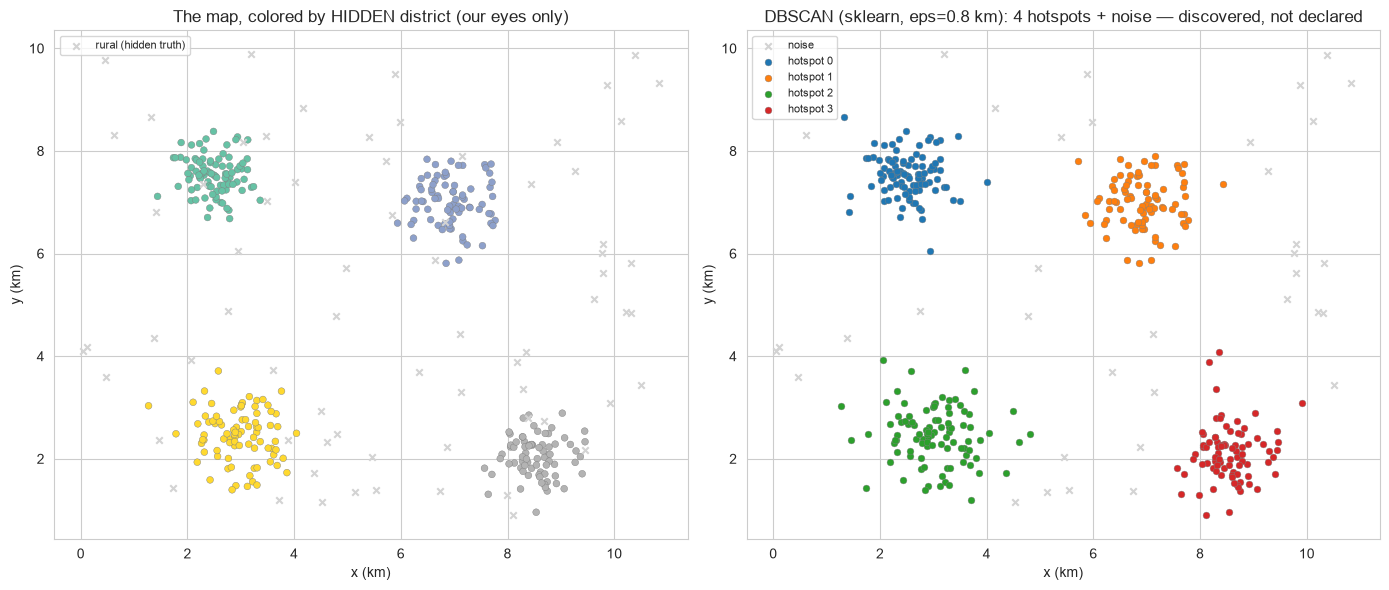


💡 Why this is DBSCAN's native habitat:
  • eps is a REAL-WORLD radius — the parameter has a physical reading anyone can challenge
  • k was never declared: the hotspots exist because their pickup density clears the bar
  • the rural ×'s are the deliverable: 'no dense place within 0.8 km' = route them to review
  • K-Means would have carved the map into 4 Voronoi sectors — rural pickups 'belonging'
    to whichever centroid happened to be nearest. Density answers the actual question.


In [16]:
# Build the city map: 4 districts (dense) + rural scatter (uniform) — coordinates in km
np.random.seed(11)

district_specs = [
    ("old town",    (2.5, 7.5), 0.40, 90),
    ("station",     (7.0, 7.0), 0.45, 80),
    ("market",      (3.0, 2.5), 0.50, 85),
    ("tech park",   (8.5, 2.0), 0.40, 75),
]
xs_city, ys_city, district_true = [], [], []
for d_id, (name, (cx, cy), spread, n) in enumerate(district_specs):
    xs_city.append(np.random.normal(cx, spread, n))
    ys_city.append(np.random.normal(cy, spread, n))
    district_true.extend([d_id] * n)

xs_rural = np.random.uniform(0, 11, 70)
ys_rural = np.random.uniform(0, 10, 70)
xs_city.append(xs_rural); ys_city.append(ys_rural)
district_true.extend([-1] * 70)                     # rural = no district (the truth is "nothing")

X_city = np.column_stack([np.concatenate(xs_city), np.concatenate(ys_city)])
y_district = np.array(district_true)
is_rural = y_district == -1

# eps is a PHYSICAL choice here: 0.8 km = the radius inside which pickups belong to one stop zone
EPS_KM, MS_CITY = 0.8, 8

print("=" * 60)
print("REAL-WORLD EXAMPLE 1: HOTSPOT DETECTION ON A CITY MAP")
print("=" * 60)
print(f"\n📊 Simulated map: {len(X_city)} pickups across an 11 × 10 km city")
print(f"  Hidden truth: {len(district_specs)} districts + {int(is_rural.sum())} rural pickups")
print(f"  eps = {EPS_KM} km (a physical radius — 'one stop zone'), min_samples = {MS_CITY}")

# Fit BOTH engines on the map (dual-engine, same contract as §6)
db_city_scratch = DBSCANScratch(eps=EPS_KM, min_samples=MS_CITY).fit(X_city)
db_city_sk = DBSCAN(eps=EPS_KM, min_samples=MS_CITY).fit(X_city)

lab_scratch, lab_sk = db_city_scratch.labels_, db_city_sk.labels_
found_city = len(set(lab_scratch)) - (1 if -1 in lab_scratch else 0)
ari_city_engines = adjusted_rand_score(lab_scratch, lab_sk)

print(f"\n📈 Discovered: {found_city} hotspot(s) — k was never declared")
print(f"  noise (rural + fringe): {(lab_scratch == -1).sum()} rows ({(lab_scratch == -1).mean():.0%})")
print(f"  🤝 scratch vs sklearn agreement on the map: ARI = {ari_city_engines:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(X_city[~is_rural, 0], X_city[~is_rural, 1], c=y_district[~is_rural], cmap="Set2",
                s=24, edgecolors="gray", linewidths=0.3)
axes[0].scatter(X_city[is_rural, 0], X_city[is_rural, 1], c="lightgray", marker="x", s=22, label="rural (hidden truth)")
axes[0].set_title("The map, colored by HIDDEN district (our eyes only)")
axes[0].set_xlabel("x (km)"); axes[0].set_ylabel("y (km)"); axes[0].legend(fontsize=8)

for k_c in np.unique(lab_sk):
    m_k = lab_sk == k_c
    if k_c == -1:
        axes[1].scatter(X_city[m_k, 0], X_city[m_k, 1], c="lightgray", marker="x", s=22, label="noise")
    else:
        axes[1].scatter(X_city[m_k, 0], X_city[m_k, 1], s=24, label=f"hotspot {k_c}", edgecolors="gray", linewidths=0.3)
axes[1].set_title(f"DBSCAN (sklearn, eps={EPS_KM} km): {found_city} hotspots + noise — discovered, not declared")
axes[1].set_xlabel("x (km)"); axes[1].set_ylabel("y (km)"); axes[1].legend(fontsize=8, loc="upper left")

plt.tight_layout()
plt.show()

print("\n💡 Why this is DBSCAN's native habitat:")
print("  • eps is a REAL-WORLD radius — the parameter has a physical reading anyone can challenge")
print("  • k was never declared: the hotspots exist because their pickup density clears the bar")
print("  • the rural ×'s are the deliverable: 'no dense place within 0.8 km' = route them to review")
print("  • K-Means would have carved the map into 4 Voronoi sectors — rural pickups 'belonging'")
print("    to whichever centroid happened to be nearest. Density answers the actual question.")

HOTSPOT PROFILES (the segmentation deliverable)
         pickups  center_x  center_y district likely
hotspot                                             
0             98      2.52      7.53        old town
1             86      6.93      7.00         station
2             95      3.02      2.46          market
3             84      8.55      2.11       tech park

🚩 The noise list (37 pickups) — 'no dense place within 0.8 km':
  rural pickups flagged: 37 of 70
  district pickups flagged (near-district strays): 0
  rural pickups adopted as border members: 33 (close enough to a hotspot's core)


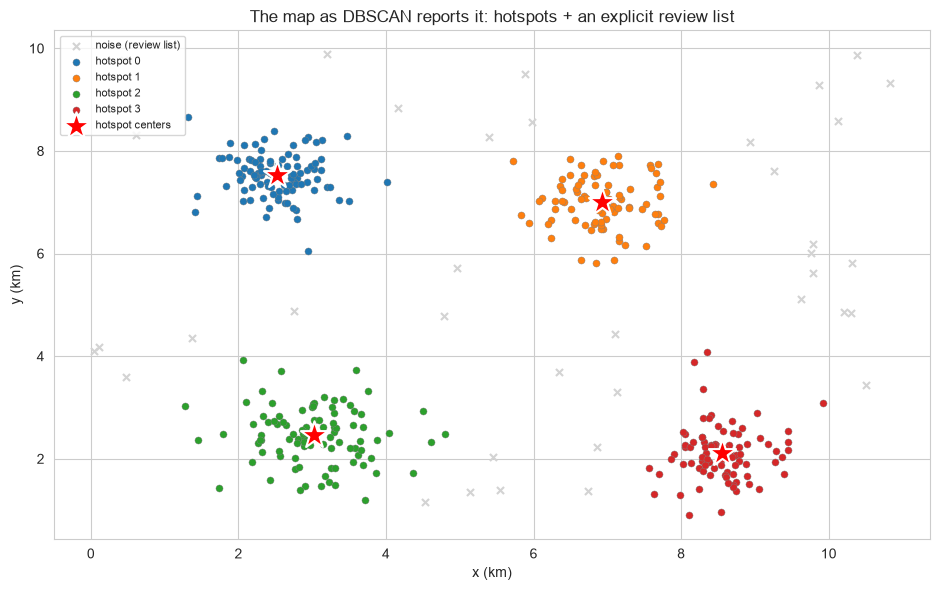


💡 The operational reading:
  • hotspots → staffing/routing decisions (profile table above)
  • noise list → the review queue — a ranked, explicit 'belongs to nothing' set
  • the adopted border pickups (rural rows close to a district) ride along with the nearest
    cluster — the §3 fine print, visible in a business decision


In [17]:
# The deliverable, tabled: hotspot profiles + the noise list
df_city = pd.DataFrame(X_city, columns=["x_km", "y_km"])
df_city["hotspot"] = db_city_sk.labels_

profile_city = df_city[df_city.hotspot >= 0].groupby("hotspot").agg(
    pickups=("hotspot", "size"),
    center_x=("x_km", "mean"),
    center_y=("y_km", "mean"),
).round(2)
profile_city["district likely"] = [district_specs[int(np.argmin(
    [( (p.center_x - cx)**2 + (p.center_y - cy)**2 ) for (_, (cx, cy), _, _) in district_specs]
))][0] for p in profile_city.itertuples()]

print("=" * 60)
print("HOTSPOT PROFILES (the segmentation deliverable)")
print("=" * 60)
print(profile_city.to_string())

noise_rows = df_city[df_city.hotspot == -1]
print(f"\n🚩 The noise list ({len(noise_rows)} pickups) — 'no dense place within {EPS_KM} km':")
print(f"  rural pickups flagged: {(is_rural & (lab_sk == -1)).sum()} of {int(is_rural.sum())}")
print(f"  district pickups flagged (near-district strays): {((~is_rural) & (lab_sk == -1)).sum()}")

# Where did the un-flagged rural pickups go? Adopted as border members of a nearby hotspot
adopted = (is_rural & (lab_sk >= 0)).sum()
print(f"  rural pickups adopted as border members: {adopted} (close enough to a hotspot's core)")

fig, ax = plt.subplots(figsize=(9.5, 6))
for k_c in np.unique(lab_sk):
    m_k = lab_sk == k_c
    if k_c == -1:
        ax.scatter(X_city[m_k, 0], X_city[m_k, 1], c="lightgray", marker="x", s=26, label="noise (review list)")
    else:
        ax.scatter(X_city[m_k, 0], X_city[m_k, 1], s=26, label=f"hotspot {k_c}", edgecolors="gray", linewidths=0.3)
ax.scatter(profile_city.center_x, profile_city.center_y, marker="*", s=420, c="red",
           edgecolors="white", linewidths=1.5, label="hotspot centers", zorder=6)
ax.set_title("The map as DBSCAN reports it: hotspots + an explicit review list")
ax.set_xlabel("x (km)"); ax.set_ylabel("y (km)"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

print("\n💡 The operational reading:")
print("  • hotspots → staffing/routing decisions (profile table above)")
print("  • noise list → the review queue — a ranked, explicit 'belongs to nothing' set")
print("  • the adopted border pickups (rural rows close to a district) ride along with the nearest")
print("    cluster — the §3 fine print, visible in a business decision")

REAL-WORLD EXAMPLE 2: IRIS SPECIES AS DENSITY REGIONS (PETAL PLANE)

📊 150 flowers × 2 raw measurements (petal length & width, cm)
  k-distance knee suggests eps ≈ 0.10 cm (min_samples=5, incl. self)

📈 Fitted at eps=0.6 cm: 2 clusters, 0 noise rows

📊 Cluster × species crosstab:
true species   setosa  versicolor  virginica
found cluster                               
0                  50           0          0
1                   0          50         50

🔍 ARI vs species labels (truth used ONLY for this check): 0.5681


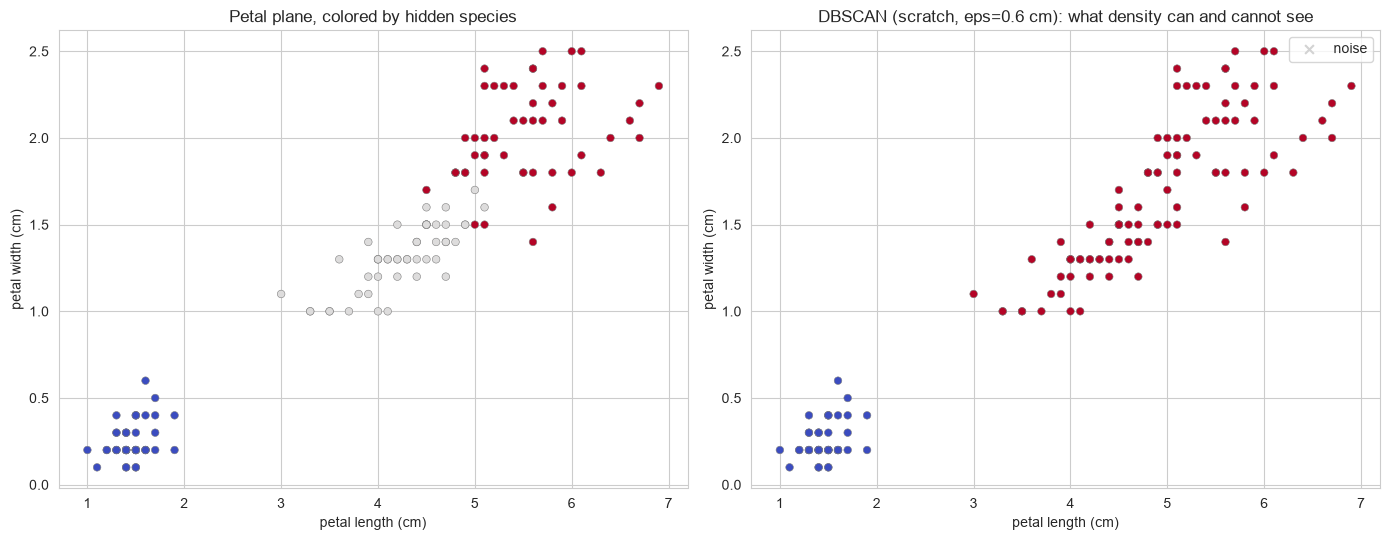


💡 The honest reading — two clusters where the textbooks show three:
  • setosa is a DENSITY ISLAND: mean-to-mean ~3 cm and nearest-member ~1.1 cm from the
    rest — recovered as its own cluster, pure in the crosstab, and it stays separate
    across any eps from ~0.3 up to ~1 cm (past that, it welds onto the big region)
  • versicolor and virginica overlap in petal space: their density is CONTINUOUS — there is
    no dip for DBSCAN to find, so it reports one region instead of inventing a boundary
  • that is an ANSWER, not a failure: 'these two species are not density-separated' —
    exactly the honest negative K-Means (k=3) papers over by splitting wherever told
  • caution for tabular habit: this worked in a 2-D raw-unit slice; on the standardized
    4-D full iris, distances concentrate, the knee flattens, and eps becomes guesswork (§3)


In [18]:
# Example 2 — iris on the PETAL PLANE (real data, 2-D slice, raw cm units: DBSCAN's comfortable regime)
iris_bundled = load_iris()
X_petal = iris_bundled.data[:, 2:4]                     # petal length × petal width, RAW cm
y_species = iris_bundled.target
species_names = iris_bundled.target_names

print("=" * 60)
print("REAL-WORLD EXAMPLE 2: IRIS SPECIES AS DENSITY REGIONS (PETAL PLANE)")
print("=" * 60)
print(f"\n📊 {X_petal.shape[0]} flowers × 2 raw measurements (petal length & width, cm)")

# The §7 recipe, applied for real: knee plot → eps
nn_iris = NearestNeighbors(n_neighbors=5).fit(X_petal)
kth_iris = nn_iris.kneighbors(X_petal)[0][:, -1]
y_curve_iris = np.sort(kth_iris)[::-1]
x_norm_iris = np.linspace(0, 1, len(y_curve_iris))
y_norm_iris = (y_curve_iris - y_curve_iris.min()) / (y_curve_iris.max() - y_curve_iris.min() + 1e-12)
chord_iris = y_norm_iris[0] + (y_norm_iris[-1] - y_norm_iris[0]) * x_norm_iris
eps_iris_knee = float(y_curve_iris[int(np.argmax(y_norm_iris - chord_iris))])
print(f"  k-distance knee suggests eps ≈ {eps_iris_knee:.2f} cm (min_samples=5, incl. self)")

# We fit at eps=0.6 — comfortably above every group's within-cluster spacing and below
# setosa's ~1.1 cm weld distance; sweep eps ±0.15 and watch the partition hold.
EPS_IRIS = 0.6
db_iris = DBSCANScratch(eps=EPS_IRIS, min_samples=5).fit(X_petal)
lab_iris = db_iris.labels_
n_iris = len(set(lab_iris)) - (1 if -1 in lab_iris else 0)

print(f"\n📈 Fitted at eps={EPS_IRIS} cm: {n_iris} clusters, {(lab_iris == -1).sum()} noise rows")
crosstab_iris = pd.crosstab(pd.Series(lab_iris, name="found cluster"),
                            pd.Series([species_names[t] for t in y_species], name="true species"))
print("\n📊 Cluster × species crosstab:")
print(crosstab_iris.to_string())
ari_iris = adjusted_rand_score(y_species, lab_iris)
print(f"\n🔍 ARI vs species labels (truth used ONLY for this check): {ari_iris:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(X_petal[:, 0], X_petal[:, 1], c=y_species, cmap="coolwarm", s=30, edgecolors="gray", linewidths=0.4)
axes[0].set_title("Petal plane, colored by hidden species")
axes[0].set_xlabel("petal length (cm)"); axes[0].set_ylabel("petal width (cm)")

mask_no = lab_iris == -1
axes[1].scatter(X_petal[mask_no, 0], X_petal[mask_no, 1], c="lightgray", marker="x", s=40, label="noise")
axes[1].scatter(X_petal[~mask_no, 0], X_petal[~mask_no, 1], c=lab_iris[~mask_no], cmap="coolwarm",
                s=30, edgecolors="gray", linewidths=0.4)
axes[1].set_title(f"DBSCAN (scratch, eps={EPS_IRIS} cm): what density can and cannot see")
axes[1].set_xlabel("petal length (cm)"); axes[1].set_ylabel("petal width (cm)")
axes[1].legend()
plt.tight_layout()
plt.show()

print("\n💡 The honest reading — two clusters where the textbooks show three:")
print("  • setosa is a DENSITY ISLAND: mean-to-mean ~3 cm and nearest-member ~1.1 cm from the")
print("    rest — recovered as its own cluster, pure in the crosstab, and it stays separate")
print("    across any eps from ~0.3 up to ~1 cm (past that, it welds onto the big region)")
print("  • versicolor and virginica overlap in petal space: their density is CONTINUOUS — there is")
print("    no dip for DBSCAN to find, so it reports one region instead of inventing a boundary")
print("  • that is an ANSWER, not a failure: 'these two species are not density-separated' —")
print("    exactly the honest negative K-Means (k=3) papers over by splitting wherever told")
print("  • caution for tabular habit: this worked in a 2-D raw-unit slice; on the standardized")
print("    4-D full iris, distances concentrate, the knee flattens, and eps becomes guesswork (§3)")

---

## 11. Comparison with Other Algorithms

### The Clustering Algorithm Field Guide (from DBSCAN's point of view)

| Aspect | **DBSCAN** | K-Means | Hierarchical (agglomerative) | GMM | HDBSCAN |
|---|---|---|---|---|---|
| **Need k upfront?** | ❌ **discovered** | ✅ yes | cut decides (you pass `n_clusters`) | ✅ yes (`n_components`) | ❌ discovered |
| **Cluster shapes** | **any** (density-chained) | convex Voronoi cells | linkage-dependent | ellipsoids | any (hierarchy of cuts) |
| **Outlier handling** | **labels noise (-1)** | must join a cluster | must join a cluster | soft, no noise class | labels noise (-1) |
| **Assignments** | hard | hard | hard | **soft (probabilities)** | hard + `probabilities_` |
| **Predict for new rows** | ❌ (transductive) | ✅ `.predict()` | ❌ (transductive) | ✅ `.predict()` | ❌ (transductive) |
| **Randomness** | none (row order only) | seeds + restarts | none | seeds + init | none |
| **Cost** | O(n²) brute / O(n log n) indexed — heavy | O(n·k·m·i) — cheapest | O(n²) — the wall | EM — moderate | heavier than DBSCAN |
| **Feature scaling** | eps-in-units duty (§4) | **required** | **required** (ward doubly) | **required** | same duty as DBSCAN |
| **Hyperparams** | eps, min_samples | k, init, n_init | n_clusters, linkage, metric | n_components, covariance_type | min_cluster_size, min_samples |
| **Worst enemy** | **varying density** | non-convex shapes | big n | too few samples | heavy tails / tiny n |
| **Bonus sibling** | OPTICS (reachability) | MiniBatchKMeans | Birch | BayesianGaussianMixture | `cluster_selection_method` |

### When to Choose Which

**Choose DBSCAN when…** shapes are arbitrary, outliers must be flagged, k is unknown — and
your density is roughly uniform. The classic; cheap, transparent, deterministic.

**Choose K-Means when…** speed and scale matter, blobs are the truth, and new rows must be
assigned later.

**Choose Hierarchical when…** n is modest, you want the full merge tree / taxonomy, or
single-linkage connectedness for non-convex structure.

**Choose GMM when…** you need soft memberships, ellipsoidal clusters, or likelihood (BIC).

**Choose HDBSCAN when…** densities vary across clusters — the case flat DBSCAN provably
cannot handle. It keeps DBSCAN's noise honesty and arbitrary shapes while letting each
cluster live at its own density.

### Practical Comparison — three geometries, six clusterers

In [19]:
# The varying-density test case: a dense core sitting INSIDE a diffuse halo — no single eps can serve both
np.random.seed(13)
core_disk = np.random.normal(0, 0.35, size=(300, 2))                 # dense blob
angle_h = np.random.uniform(0, 2 * np.pi, 150)
radius_h = 3.0 * np.sqrt(np.random.uniform(0, 1, 150))               # uniform disk (diffuse halo)
halo_disk = np.column_stack([radius_h * np.cos(angle_h), radius_h * np.sin(angle_h)])
X_target = np.vstack([core_disk, halo_disk])
y_target = np.array([0] * 300 + [1] * 150)                           # truth: two groups, 6× density contrast

def make_algorithms(k):
    return {
        "K-Means": KMeans(n_clusters=k, n_init=10, random_state=42),
        "Agglomerative (ward)": AgglomerativeClustering(n_clusters=k, linkage="ward"),
        "Agglomerative (single)": AgglomerativeClustering(n_clusters=k, linkage="single"),
        "GMM": GaussianMixture(n_components=k, random_state=42),
        "DBSCAN": DBSCAN(eps=0.6, min_samples=5),                    # k-free: eps tuned per §7's sweep logic
        "HDBSCAN": HDBSCAN(min_cluster_size=15),
    }

TASKS = {
    "blobs": dict(X=X_blobs, truth=y_true_blobs, k=4),
    "rings": dict(X=X_rings, truth=y_rings, k=2),
    "target (varying density)": dict(X=X_target, truth=y_target, k=2),
}

results_db = {}
for data_name, task in TASKS.items():
    X_data, y_truth = task["X"], task["truth"]
    for name, algo in make_algorithms(task["k"]).items():
        t0 = time.time()
        if name == "GMM":
            algo.fit(X_data)
            labels_alg = algo.predict(X_data)
        else:
            labels_alg = algo.fit_predict(X_data)
        elapsed = time.time() - t0

        n_found = len(set(labels_alg)) - (1 if -1 in labels_alg else 0)
        mask = labels_alg != -1
        if len(set(labels_alg[mask])) >= 2 and mask.sum() > n_found:
            sil_val = silhouette_score(X_data[mask], labels_alg[mask])
        else:
            sil_val = np.nan

        results_db[(data_name, name)] = {
            "labels": labels_alg,
            "ARI": adjusted_rand_score(y_truth, labels_alg),
            "silhouette": sil_val,
            "time_s": elapsed,
            "n_found": n_found,
        }

rows_db = []
for (data_name, name), r in results_db.items():
    rows_db.append({
        "Dataset": data_name,
        "Algorithm": name,
        "Clusters found": r["n_found"],
        "Silhouette": round(r["silhouette"], 3) if not np.isnan(r["silhouette"]) else "n/a",
        "ARI vs truth": round(r["ARI"], 3),
        "Time (s)": round(r["time_s"], 3),
    })
df_db = pd.DataFrame(rows_db)

print("=" * 78)
print("ALGORITHM COMPARISON — BLOBS vs RINGS vs VARYING-DENSITY TARGET")
print("=" * 78)
print(df_db.to_string(index=False))

print("\n💡 Reading the table:")
print("  • On BLOBS everyone recovers the four groups — the easy case stays easy")
print("  • On RINGS only the density/chain engines (DBSCAN, single-linkage) trace the structure;")
print("    K-Means / GMM / ward slice by sector (nb 12's disease)")
print("  • On the TARGET the roles INVERT: a dense core inside a diffuse halo defeats flat")
print("    DBSCAN — the halo's core-eps exceeds the halo-core bridge distance, so no single eps")
print("    yields both groups: sweep it and the halo is either noise or welded into the core.")
print("    Watch HDBSCAN's row: the varying cut recovers both groups (a few of the halo's")
print("    sparsest rows may shed as noise — density methods are honest about boundaries)")

ALGORITHM COMPARISON — BLOBS vs RINGS vs VARYING-DENSITY TARGET
                 Dataset              Algorithm  Clusters found Silhouette  ARI vs truth  Time (s)
                   blobs                K-Means               4      0.814         1.000     0.053
                   blobs   Agglomerative (ward)               4      0.814         1.000     0.006
                   blobs Agglomerative (single)               4      0.814         1.000     0.003
                   blobs                    GMM               4      0.814         1.000     0.011
                   blobs                 DBSCAN               4      0.832         0.887     0.002
                   blobs                HDBSCAN               4      0.814         1.000     0.010
                   rings                K-Means               2      0.342        -0.002     0.040
                   rings   Agglomerative (ward)               2      0.325        -0.001     0.004
                   rings Agglomerative (singl

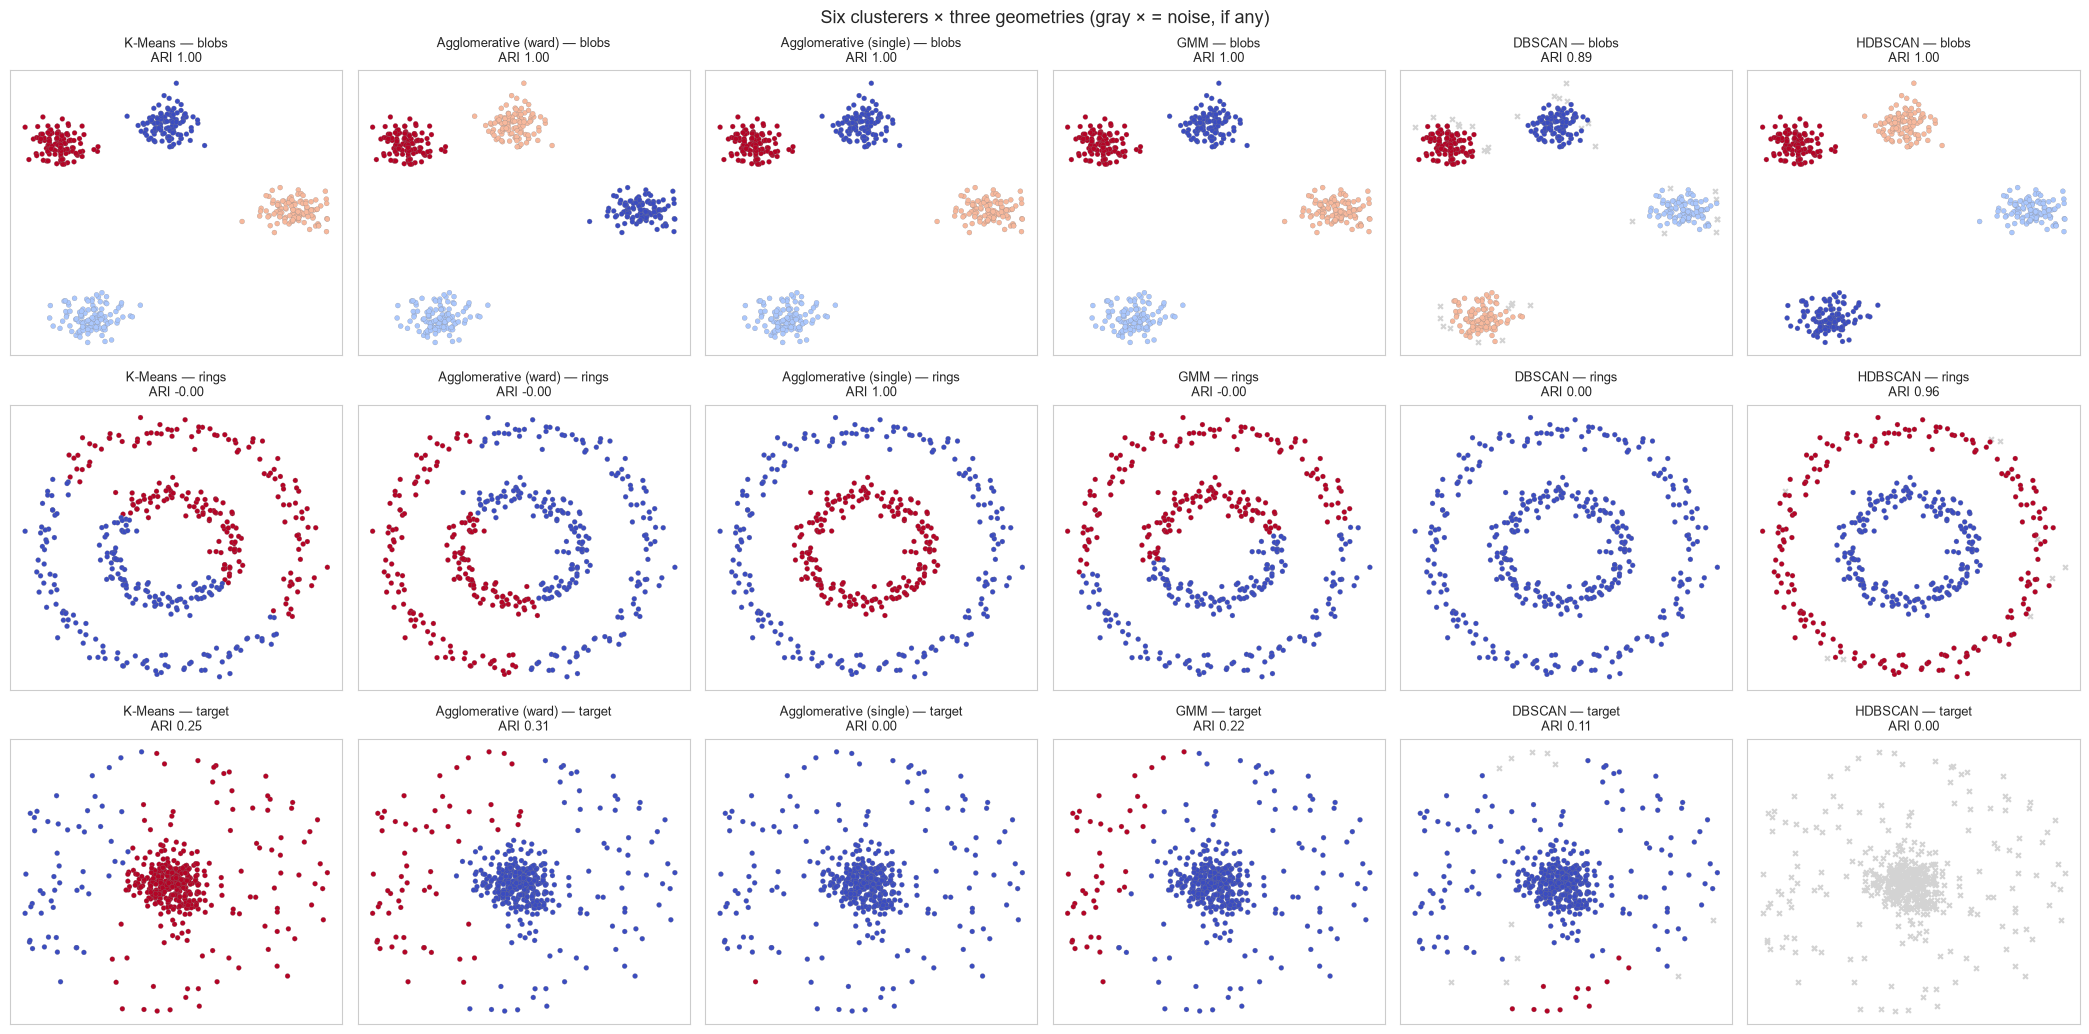


⚠️ One number never tells the story: silhouette flatters chained and sector partitions;
   ARI needs truth, which real projects don't have — budget a human cluster review.

💡 Field notes from DBSCAN's chair:
✅ DBSCAN:
  • discovers k and flags noise — the shape champion on uniform-ish density
  • eps lives in your data's units; the knee plot is the honest way to choose it
  • no predict — plan the nearest-core path if new rows must be labeled
✅ HDBSCAN (the upgrade path):
  • keeps DBSCAN's honesty (noise labels, arbitrary shapes) while letting each cluster
    live at its own density — the target dataset's only correct row
  • heavier, and cluster ids/persistence take a moment to learn
✅ The rest of the family:
  • K-Means: fastest + predicts; pay with convex blobs and absorbed outliers
  • Agglomerative: the dendrogram + four geometries; pay with O(n²) and no noise class
  • GMM: soft memberships + ellipses; pay with EM cost and no noise class


In [20]:
# Visualize all 18 partitions: six algorithms × three geometries
algo_order = ["K-Means", "Agglomerative (ward)", "Agglomerative (single)", "GMM", "DBSCAN", "HDBSCAN"]

fig, axes = plt.subplots(3, 6, figsize=(21, 10.5))
for row, data_name in enumerate(["blobs", "rings", "target (varying density)"]):
    X_data = {"blobs": X_blobs, "rings": X_rings, "target (varying density)": X_target}[data_name]
    for col, name in enumerate(algo_order):
        r = results_db[(data_name, name)]
        labels_alg = r["labels"]
        noise_mask = labels_alg == -1
        ax = axes[row, col]
        ax.scatter(X_data[noise_mask, 0], X_data[noise_mask, 1], c="lightgray", s=12, marker="x")
        ax.scatter(X_data[~noise_mask, 0], X_data[~noise_mask, 1], c=labels_alg[~noise_mask],
                   cmap="coolwarm", s=13, edgecolors="gray", linewidths=0.15)
        ax.set_title(f"{name} — {data_name.split(' (')[0]}\nARI {r['ARI']:.2f}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle("Six clusterers × three geometries (gray × = noise, if any)", fontsize=13)
plt.tight_layout()
plt.show()

print("\n⚠️ One number never tells the story: silhouette flatters chained and sector partitions;")
print("   ARI needs truth, which real projects don't have — budget a human cluster review.")
print("\n💡 Field notes from DBSCAN's chair:")
print("✅ DBSCAN:")
print("  • discovers k and flags noise — the shape champion on uniform-ish density")
print("  • eps lives in your data's units; the knee plot is the honest way to choose it")
print("  • no predict — plan the nearest-core path if new rows must be labeled")
print("✅ HDBSCAN (the upgrade path):")
print("  • keeps DBSCAN's honesty (noise labels, arbitrary shapes) while letting each cluster")
print("    live at its own density — the target dataset's only correct row")
print("  • heavier, and cluster ids/persistence take a moment to learn")
print("✅ The rest of the family:")
print("  • K-Means: fastest + predicts; pay with convex blobs and absorbed outliers")
print("  • Agglomerative: the dendrogram + four geometries; pay with O(n²) and no noise class")
print("  • GMM: soft memberships + ellipses; pay with EM cost and no noise class")

---

## 12. References

### 📚 Academic Papers & Books

1. **Original Work**:
   - **Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). "A Density-Based Algorithm for
     Discovering Clusters in Large Spatial Databases with Noise."** *Proc. 2nd International
     Conference on Knowledge Discovery and Data Mining (KDD '96)*, AAAI Press — the original
     DBSCAN paper (and the acronym)
   - **Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (1998). "Density-Based Clustering in
     Spatial Databases: The Algorithm GDBSCAN and Its Applications."** *Data Mining and
     Knowledge Discovery*, 2(2) — the generalized semantics and the `min_samples ≈ 2 × dims`
     rule of thumb
2. **The Modern Reckoning**:
   - **Schubert, E., Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (2017). "DBSCAN Revisited,
     Revisited: Why and How You Should (Still) Use DBSCAN."** *ACM Transactions on Database
     Systems*, 42(3) — why `eps`/`min_samples` are still (incorrectly) called "parameter-free magic"
   - **Campello, R. J. G. B., Moulavi, D., & Sander, J. (2013). "Density-Based Clustering Based
     on Hierarchical Density Estimates."** *PAKDD 2013* — HDBSCAN's origin
   - **Campello, R. J. G. B., et al. (2015). "Hierarchical Density Estimates for Data
     Clustering, Visualization, and Outlier Detection."** *ACM TKDD*, 10(1) — the full HDBSCAN treatment
   - **Ankerst, M., Breunig, M. M., Kriegel, H.-P., & Sander, J. (1999). "OPTICS: Ordering
     Points to Identify the Clustering Structure."** *SIGMOD '99* — the reachability successor
3. **Textbooks**:
   - Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*, 2nd ed. (§14.3 — clustering family context)
   - James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An Introduction to Statistical Learning* (Ch. 12 — unsupervised methods)

### 🌐 Online Resources

- [Scikit-learn DBSCAN API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- [Scikit-learn Clustering User Guide — DBSCAN section](https://scikit-learn.org/stable/modules/clustering.html#dbscan)
- [Scikit-learn Gallery: Demo of DBSCAN clustering algorithm](https://scikit-learn.org/stable/auto_examples/cluster/plot_dbscan.html) — core/border/noise coloring, the pattern §5 reuses
- [Scikit-learn Gallery: Comparing different clustering algorithms on toy datasets](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html) — the shape gallery §11 extends
- [Scikit-learn Gallery: Demo of HDBSCAN clustering algorithm](https://scikit-learn.org/stable/auto_examples/cluster/plot_hdbscan.html)
- [Scikit-learn HDBSCAN API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.HDBSCAN.html)
- [Scikit-learn OPTICS API](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.OPTICS.html)
- [The original Ester et al. paper (PDF, LMU Munich)](https://www.dbs.ifi.lmu.de/Publikationen/Papers/KDD-96.final.frame.pdf)
- [DBSCAN Revisited, Revisited (DOI)](https://doi.org/10.1145/3068335)

### 📊 Key Concepts to Master

- **eps-neighborhood & core point**: $\lvert N_\epsilon(x)\rvert \ge$ `min_samples`, **the point itself included**
- **Border vs noise**: a non-core point within `eps` of a core is border (adopted, expands nothing); unreachable is noise (-1)
- **Density-reachability & density-connectivity**: chains through CORES only; clusters = connected components of the core graph
- **Breadth-first expansion**: a list + read pointer; no recursion; index-ordered scan
- **First-come-first-served borders**: the labeling fine print; ids are cosmetic — compare partitions with ARI
- **k discovered, not declared**: cluster count = an output of density structure
- **The eps/unit coupling**: eps lives in the units you feed it — scale deliberately or reason in native units
- **k-distance knee**: the standard data-driven eps recipe (sort the `min_samples`-th NN distances, read the bend)
- **Varying density**: the single global eps's documented worst enemy — HDBSCAN's reason to exist
- **O(n²) brute memory**: the twin's honest wall; sklearn's tree indexes + `radius_neighbors_graph`/OPTICS escape hatches
- **Transductive**: no `predict` — nearest-core assignment is the consistent extension
- **Determinism**: no `random_state` anywhere; row order is the only degree of freedom

### 🔗 Related Notebooks in this Repository

- `12_clustering_kmeans.ipynb` — the flat sibling: convex Voronoi cells, `n_init` roulette, `.predict()` — DBSCAN's release from all three
- `13_clustering_hierarchical.ipynb` — the hierarchy sibling: merge trees, four linkages, single-linkage chaining — a cousin of density-chaining
- `15_pca.ipynb` — the dimensionality pre-treatment DBSCAN's eps needs in higher dimensions
- `07_k_nearest_neighbors.ipynb` — the same neighborhood machinery, pointed at supervision (DBSCAN's neighbor queries ARE KNN queries)
- `02_logistic_regression.ipynb` — the supervised contrast: what changes when labels DO exist

### 📈 Evaluation Metrics

**Internal (no ground truth):**
- Clusters found + noise share — the structural headline pair (0 = starved, 1 = welded)
- Silhouette / Davies-Bouldin / Calinski-Harabasz — on non-noise rows only (mask the -1s!)

**External (only with trusted reference labels):**
- Adjusted Rand Index (chance-corrected, permutation-invariant) — also the engine-agreement metric (§6)
- Cluster × class crosstab — the order-free sanity table (§10)

---

## Summary & Key Takeaways

### What We Learned

1. **Theory**: DBSCAN defines clusters as connected regions of density — core points chain
   breadth-first, borders get adopted, everything unreached is noise (-1); k is an *output*
2. **Math**: one eps-ball definition + one counting rule (`min_samples`, self included) generate
   the entire algorithm; no objective function, no inertia, no seeding
3. **Assumptions**: one global eps fits all clusters (varying density is the enemy); eps lives
   in the units you feed it; distance concentration limits high dimensions; borders are
   first-come-first-served
4. **Implementation**: the twin builds one (n × n) distance matrix, marks cores, grows clusters
   breadth-first in index order — and reproduces sklearn's partition exactly (ARI = 1.0, same
   noise masks — the repo's tests pin it)
5. **Hyperparameters**: `eps` (geometry — read it off the k-distance knee, never guess) and
   `min_samples` (strictness — the 2 × dims rule of thumb); everything else in sklearn is
   engine surface
6. **Tuning**: no accuracy, no GridSearchCV, no inertia elbow — knee plot + eps sweep (starve
   vs weld window) + noise share + silhouette on non-noise rows
7. **Practice**: hotspot detection on a city map (physical eps, discovered k, noise as the
   deliverable) and iris on the petal plane (a density island + one honest merged region)

### When to Use DBSCAN

✅ **Use when**:
- Noise/outliers are real and must be *flagged* (anomaly screening, fraud, sensor glitches)
- Shapes are unknown or non-convex (rings, moons, spirals, city districts)
- k is unknown — and declaring one would be a fiction
- Coordinates/spatial data where eps has a physical reading
- Determinism matters (no seeds, no restarts, same X → same labels)

❌ **Avoid when**:
- Densities vary strongly across clusters → HDBSCAN (or OPTICS) instead
- New rows must be labeled post-fit → K-Means, or the nearest-core workaround
- Data is high-dimensional without preprocessing → PCA first, or a different family
- n is huge with tight memory → dedupe/weight, chunked precomputed graphs, OPTICS, or subsample
- Soft memberships are required → GMM (or HDBSCAN's `probabilities_` as a partial answer)
- Downstream cannot tolerate an "unassigned" class → assign-everyone methods only

### Best Practices Checklist

- ✅ **Read the k-distance knee** before choosing eps (and re-read it after any rescaling)
- ✅ **Own your units** — scale mixed tabular features; keep native units on spatial data
- ✅ **min_samples ≈ 2 × dims**, higher for noisy/high-dim; never 2 "to keep everything"
- ✅ **Report the noise share** beside the cluster count — 0 or 100% are signals, not crashes
- ✅ **Mask noise out of silhouette** (and every internal metric)
- ✅ **Plan the new-row path** (nearest-core against `components_`) before deployment
- ✅ **Compare partitions with ARI** — ids and border claims are order artifacts
- ✅ **Dedupe + `sample_weight`** for duplicates; chunk/precompute for big n
- ✅ **Reach for HDBSCAN** the moment densities disagree

### Critical Requirements

**1. eps Must Mean Something in Your Units:**
```python
X_scaled = StandardScaler().fit_transform(X)   # or: keep native units and reason physically
eps = knee_from_k_distance(X_scaled, min_samples=5)
```

**2. Respect the Transductive Contract:**
- no `predict` — plan nearest-core assignment (or a refit) BEFORE deploying

**3. Respect the Density Contract:**
- one global eps — if your clusters live at different densities, that's HDBSCAN's problem to solve, not DBSCAN's

### Advantages vs Disadvantages

**Advantages:**
- ✅ k discovered; noise labeled — the two answers K-Means structurally cannot give
- ✅ Arbitrary cluster shapes via density chaining
- ✅ Deterministic — no seeding, no restarts, no local-minimum roulette
- ✅ Only two knobs, both interpretable (a radius and a friend count)
- ✅ The noise list is a first-class deliverable (anomaly screening for free)

**Disadvantages:**
- ❌ Single global eps — varying density breaks it (HDBSCAN's fix)
- ❌ No `predict` — transductive; new-row labeling needs a workaround
- ❌ O(n²) brute memory (twin); sklearn's bulk implementation has a documented worst case too
- ❌ eps in data units — meaningless defaults on raw mixed-unit features (§4's accident)
- ❌ Distance concentration in high dimensions — the knee plot degrades with dimensionality
- ❌ Border assignments are first-come-first-served — order-sensitive at cluster boundaries

### Unique Characteristic: Noise Is a First-Class Answer

Every other method in this series must assign every point somewhere. DBSCAN is the only
classic clusterer whose vocabulary includes **"belongs to nothing"** — and that one label
changes what the method can be *for*: screening, flagging, honest refusals. When the question
is "where is the structure, and what is NOT structure?", DBSCAN (or its heir HDBSCAN) is the
tool that can actually say both.

### Next Steps

1. **Practice** on real coordinate data (city open-data portals) — eps in km, noise as the deliverable
2. **Run the knee plot** on your own tabular data after `StandardScaler` — see whether a bend exists at all
3. **Try HDBSCAN** (§8/§11) on any dataset where DBSCAN's sweep showed no stable eps band
4. **Engineer features**: noise flags and nearest-hotspot distances feed supervised models well (nb 03/05/07)
5. **Compare** with K-Means/hierarchical/GMM on the same data (§11 style) — one geometry, one verdict
6. **Read** notebook 15 (PCA) — the dimensionality pre-treatment density methods lean on
7. **Reflect**: when a stakeholder asks "which customers are the segments?", DBSCAN's honest
   extra answer is "…and these 30 are nobody's" — usually the most valuable line in the report

---

**Congratulations!** You can now run, tune, and defend a DBSCAN analysis — including its
signature honest answers: *no clusters*, *one welded blob*, and a noise list that means it. 🎯🎉

**Remember**: read the knee, own your units, mask the noise out of every score — and when the
densities disagree with each other, promote the analysis to HDBSCAN instead of fighting eps.